# FL23 — 10 m FEL spectrometer
FLASH gas beamtime, November 2026 | Run 60609

Inspect the camera images, integrate the spatial axis and estimate the fraction of spectra with one or several resolved spectral peaks. Sections 1–5 inspect the selected file; section 6 can classify all files of the run. Camera frames are not assumed to be individual FEL pulses until the exposure and trigger are confirmed.

## 1. Imports and configuration

In [1]:
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, savgol_filter

In [8]:
BASE_DIR = Path('/asap3/flash/gpfs/fl24/2026/data/11024642')

RAW_H5 = BASE_DIR / 'raw/hdf/online-0/fl2user1/FLASH2_USER1_main_run60609_file1_20261126T154426.1.h5'

CAMERA_PATH = 'uncategorised/FLASH.FEL/FL23.CAM1/FL23.MSU.SRC'

IMAGE_PATH = CAMERA_PATH + '/value'
INDEX_PATH = CAMERA_PATH + '/index'

N_SPECTRAL_PIXELS = 200

print('File:', RAW_H5.name)
print('Exists:', RAW_H5.exists())
print(f'File size: {RAW_H5.stat().st_size / 1024**3:.2f} GB')

RUN = 60609
CHUNK_SIZE = 64

File: FLASH2_USER1_main_run60609_file1_20261126T154426.1.h5
Exists: True
File size: 0.52 GB


## 2. Camera structure, run files and timing
The camera index is compared with the timing and Gotthard indices. The saved first-file output showed 864 distinct camera indices, all matching timing and Gotthard; 831 of 863 increments were three trains. Matching train IDs alone does not establish which bunch or how many pulses contributed to an image.

In [9]:
with h5py.File(RAW_H5, 'r') as f:

    ds = f[IMAGE_PATH]
    camera_index = f[INDEX_PATH][:]

    n_images, n_spatial, n_spectral = ds.shape

    print('Image shape:', ds.shape)
    print('Data type:', ds.dtype)
    print('Chunks:', ds.chunks)
    print('Compression:', ds.compression)

    print('\nCamera attributes:')
    print(dict(f[CAMERA_PATH].attrs))
    print(dict(ds.attrs))

    print('\nCamera index:')
    print('Shape:', camera_index.shape)
    print('First 20:', camera_index[:20])
    print('Last 20:', camera_index[-20:])
    print('Unique indices:', len(np.unique(camera_index)))

    print('\nTiming indices:')
    print(f['Timing/event ID/index'][:20])

    print('\nTiming event IDs:')
    print(f['Timing/event ID/value'][:20])

assert n_spectral == N_SPECTRAL_PIXELS
assert len(camera_index) == n_images

Image shape: (864, 700, 200)
Data type: uint16
Chunks: (1, 700, 200)
Compression: gzip

Camera attributes:
{}
{'DAQ name': 'FLASH.FEL/FL23.CAM1/FL23.MSU.SRC', 'DOOCS name': 'ImageExt', 'description': 'Image at FLASH.FEL/FL23.CAM1/FL23.MSU.SRC', 'dim': '0', 'height': np.int64(700), 'offset': array([ 859, 1869]), 'width': np.int64(200)}

Camera index:
Shape: (864,)
First 20: [2809426666 2809426669 2809426672 2809426675 2809426678 2809426681
 2809426684 2809426687 2809426690 2809426693 2809426696 2809426699
 2809426702 2809426705 2809426708 2809426711 2809426714 2809426717
 2809426720 2809426723]
Last 20: [2809429252 2809429255 2809429258 2809429261 2809429264 2809429267
 2809429270 2809429273 2809429276 2809429279 2809429282 2809429285
 2809429288 2809429291 2809429294 2809429297 2809429300 2809429303
 2809429306 2809429309]
Unique indices: 864

Timing indices:
[2809426666 2809426667 2809426668 2809426669 2809426670 2809426671
 2809426672 2809426673 2809426674 2809426675 2809426676 28094

In [10]:
with h5py.File(RAW_H5, 'r') as f:

    timing_index = f['Timing/event ID/index'][:]
    timing_event_id = f['Timing/event ID/value'][:]

    gotthard_index = f['FL2/Support Infrastructure/Gotthard/images/index'][:]

print('Camera images:', len(camera_index))
print('Timing entries:', len(timing_index))
print('Gotthard entries:', len(gotthard_index))

print('\nCamera indices found in timing index:',
      np.isin(camera_index, timing_index).mean() * 100, '%')

print('Camera indices found in timing event IDs:',
      np.isin(camera_index, timing_event_id).mean() * 100, '%')

print('Camera indices found in Gotthard index:',
      np.isin(camera_index, gotthard_index).mean() * 100, '%')

print('\nMost common camera index increments:')

steps, counts = np.unique(
    np.diff(camera_index.astype(np.int64)),
    return_counts=True
)

for i in np.argsort(counts)[-10:][::-1]:
    print(f'{steps[i]:10d} : {counts[i]:6d}')

Camera images: 864
Timing entries: 2657
Gotthard entries: 2657

Camera indices found in timing index: 100.0 %
Camera indices found in timing event IDs: 100.0 %
Camera indices found in Gotthard index: 100.0 %

Most common camera index increments:
         3 :    831
         6 :     16
         4 :      7
         2 :      5
         5 :      3
         1 :      1


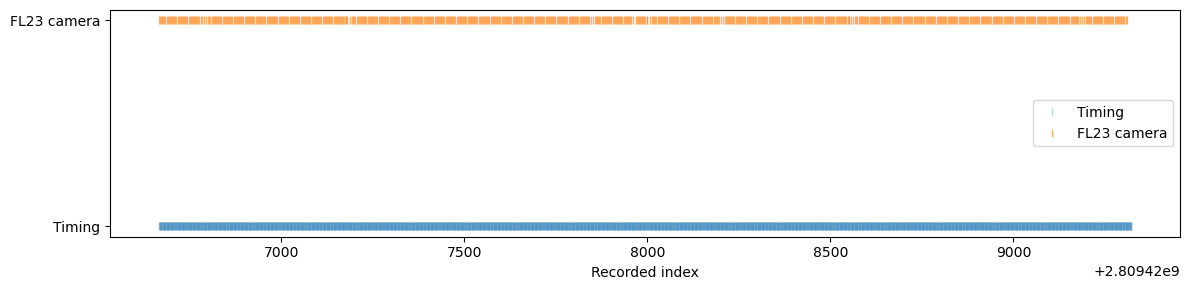

In [11]:
fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(timing_index, np.zeros(len(timing_index)),
        '|', label='Timing', alpha=0.3)

ax.plot(camera_index, np.ones(len(camera_index)),
        '|', label='FL23 camera', alpha=0.6)

ax.set_yticks([0, 1])
ax.set_yticklabels(['Timing', 'FL23 camera'])
ax.set_xlabel('Recorded index')
ax.legend()

fig.tight_layout()
plt.show()

In [12]:
raw_files = sorted(
    RAW_H5.parent.glob(f'*run{RUN}_file*.h5')
)

n_total = 0

for path in raw_files:

    with h5py.File(path, 'r') as f:

        if IMAGE_PATH not in f:
            print(path.name, '| No camera data')
            continue

        shape = f[IMAGE_PATH].shape
        n_total += shape[0]

        print(path.name, '|', shape)

print('\nNumber of files:', len(raw_files))
print(f'Total camera images: {n_total:,}')

print(f'Integrated spectra memory (float64): '
      f'{n_total * n_spectral * 8 / 1024**2:.2f} MiB')

FLASH2_USER1_main_run60609_file1_20261126T154426.1.h5 | (864, 700, 200)

Number of files: 1
Total camera images: 864
Integrated spectra memory (float64): 1.32 MiB


## 3. Individual camera images and raw spectra
The 700-pixel spatial dimension is summed, leaving the 200 spectral pixels. No corrections are applied here.

In [13]:
N_EXAMPLES = 12

rng = np.random.default_rng(42)

example_indices = np.sort(
    rng.choice(n_images, size=min(N_EXAMPLES, n_images),
               replace=False)
)

with h5py.File(RAW_H5, 'r') as f:

    images = f[IMAGE_PATH][example_indices]

# Collapse the spatial axis
spectra = images.sum(axis=1, dtype=np.float64)

pixels = np.arange(n_spectral)

print('Images:', images.shape)
print('Spectra:', spectra.shape)
print('Image memory:', images.nbytes / 1024**2, 'MiB')

Images: (12, 700, 200)
Spectra: (12, 200)
Image memory: 3.204345703125 MiB


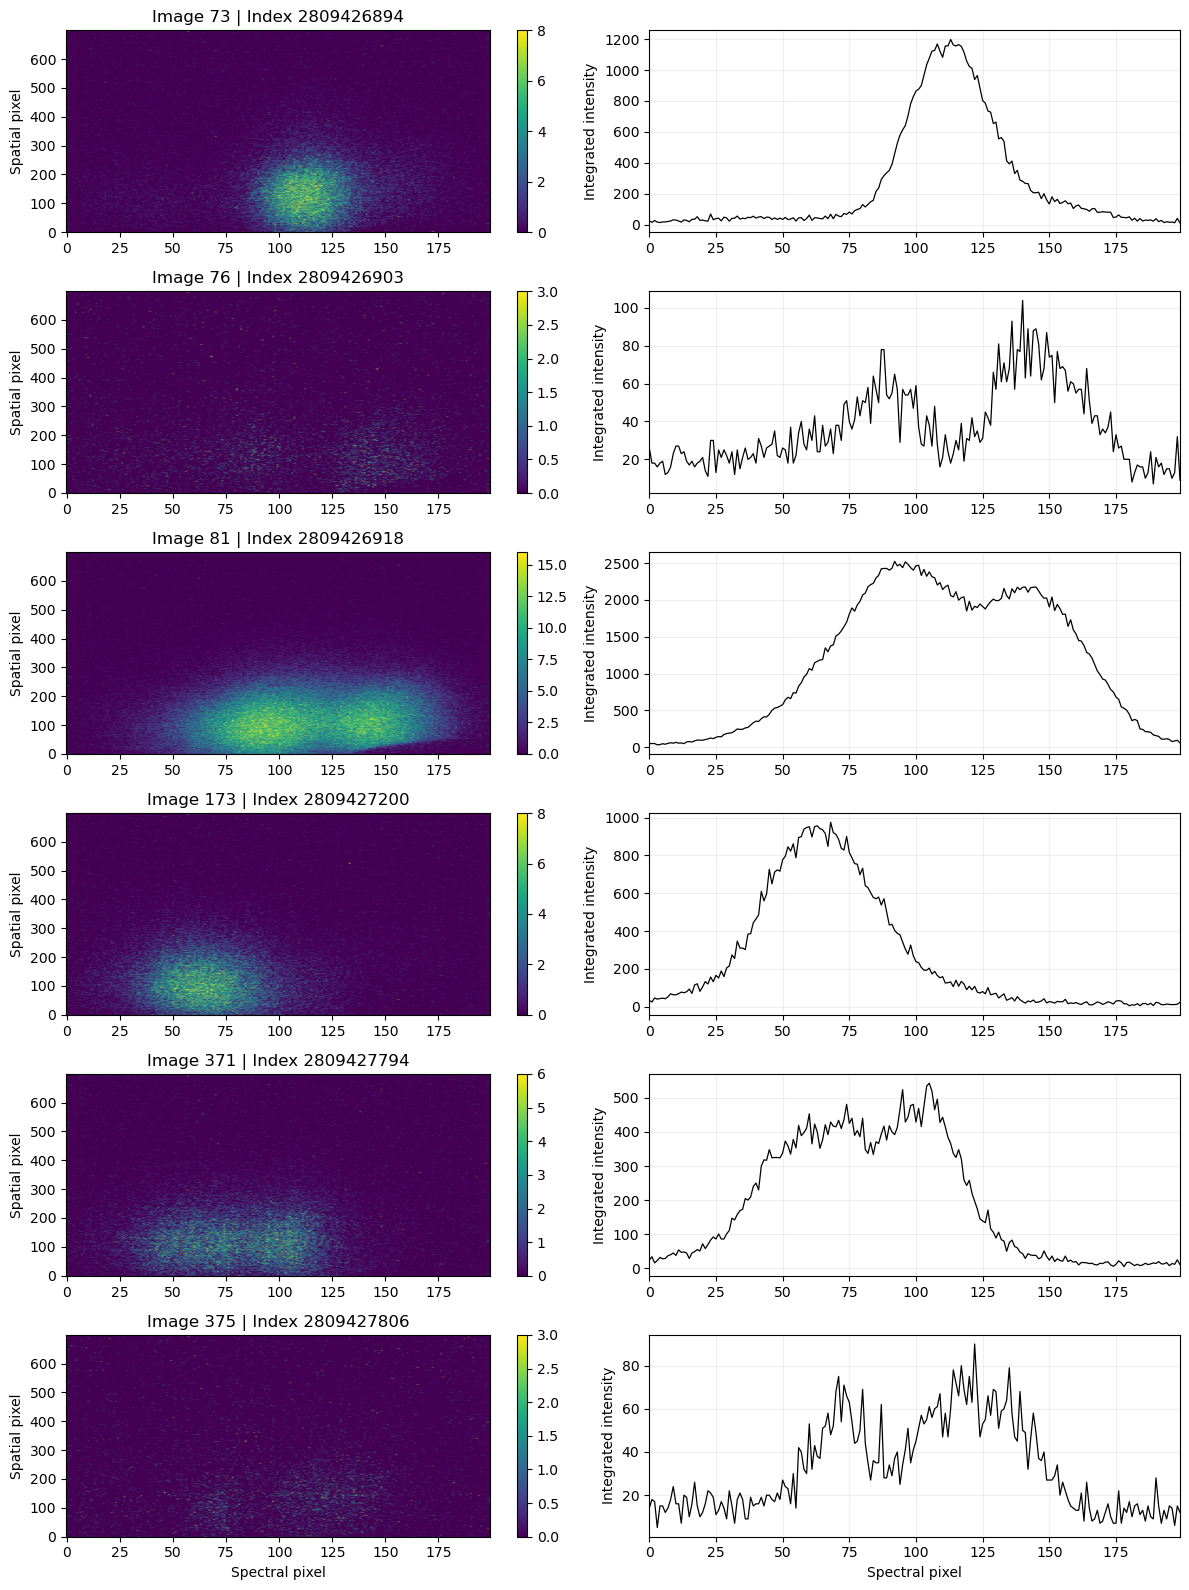

In [14]:
fig, axs = plt.subplots(6, 2, figsize=(12, 16))

for i, (ax_im, ax_spec) in enumerate(axs):

    img = images[i]
    spec = spectra[i]

    im = ax_im.imshow(img, origin='lower', aspect='auto',
                      cmap='viridis',
                      vmin=np.percentile(img, 5),
                      vmax=np.percentile(img, 99.9))

    fig.colorbar(im, ax=ax_im)

    ax_im.set_title(f'Image {example_indices[i]} | '
                    f'Index {camera_index[example_indices[i]]}')

    ax_im.set_ylabel('Spatial pixel')

    ax_spec.plot(pixels, spec, color='k', lw=0.9)
    ax_spec.set_ylabel('Integrated intensity')
    ax_spec.set_xlim(0, n_spectral - 1)
    ax_spec.grid(alpha=0.2)

axs[-1, 0].set_xlabel('Spectral pixel')
axs[-1, 1].set_xlabel('Spectral pixel')

fig.tight_layout()
plt.show()

## 4. Mean camera image and spatial profile
Use this diagnostic to choose signal and background regions. In the supplied mean image the signal is mostly below spatial pixel 350–400, with very little above 450.

In [15]:
CHUNK_SIZE = 64

mean_image = np.zeros((n_spatial, n_spectral),
                      dtype=np.float64)

with h5py.File(RAW_H5, 'r') as f:

    ds = f[IMAGE_PATH]

    for start in range(0, n_images, CHUNK_SIZE):

        chunk = ds[start:start + CHUNK_SIZE]

        mean_image += chunk.sum(axis=0, dtype=np.float64)

mean_image /= n_images

spatial_profile = mean_image.sum(axis=1)
spectral_profile = mean_image.sum(axis=0)

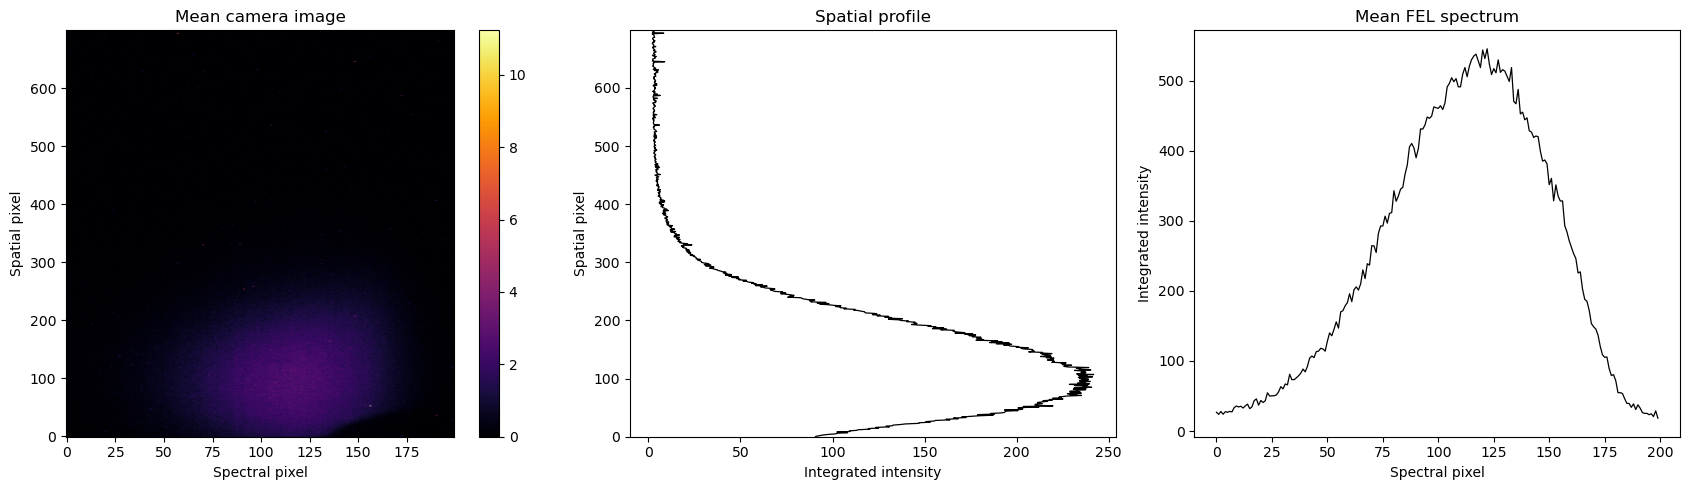

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5))

im = axs[0].imshow(mean_image, origin='lower',
                   aspect='auto', cmap='inferno')

fig.colorbar(im, ax=axs[0])

axs[0].set_xlabel('Spectral pixel')
axs[0].set_ylabel('Spatial pixel')
axs[0].set_title('Mean camera image')

axs[1].plot(spatial_profile, np.arange(n_spatial),
            color='k', lw=0.9)

axs[1].set_ylabel('Spatial pixel')
axs[1].set_xlabel('Integrated intensity')
axs[1].set_title('Spatial profile')
axs[1].set_ylim(0, n_spatial - 1)

axs[2].plot(pixels, spectral_profile, color='k', lw=0.9)
axs[2].set_xlabel('Spectral pixel')
axs[2].set_ylabel('Integrated intensity')
axs[2].set_title('Mean FEL spectrum')

fig.tight_layout()
plt.show()

## 5. Integrated spectra and 2D maps
The original full-height integration is kept for comparison. The normalised map divides each **raw spectrum by its own maximum across spectral pixels**, not by area or GMD. No background is subtracted in this map. Weak spectra can therefore appear bright.

In [17]:
SPATIAL_ROI = (0, 700)
CHUNK_SIZE = 64

spectra_all = np.empty((n_images, n_spectral),
                       dtype=np.float64)

lo, hi = SPATIAL_ROI

assert 0 <= lo < hi <= n_spatial

with h5py.File(RAW_H5, 'r') as f:

    ds = f[IMAGE_PATH]

    for start in range(0, n_images, CHUNK_SIZE):

        stop = min(start + CHUNK_SIZE, n_images)

        chunk = ds[start:stop, lo:hi, :]

        spectra_all[start:stop] = chunk.sum(
            axis=1, dtype=np.float64
        )

print('Integrated spectra:', spectra_all.shape)
print(f'Memory: {spectra_all.nbytes / 1024**2:.2f} MiB')

Integrated spectra: (864, 200)
Memory: 1.32 MiB


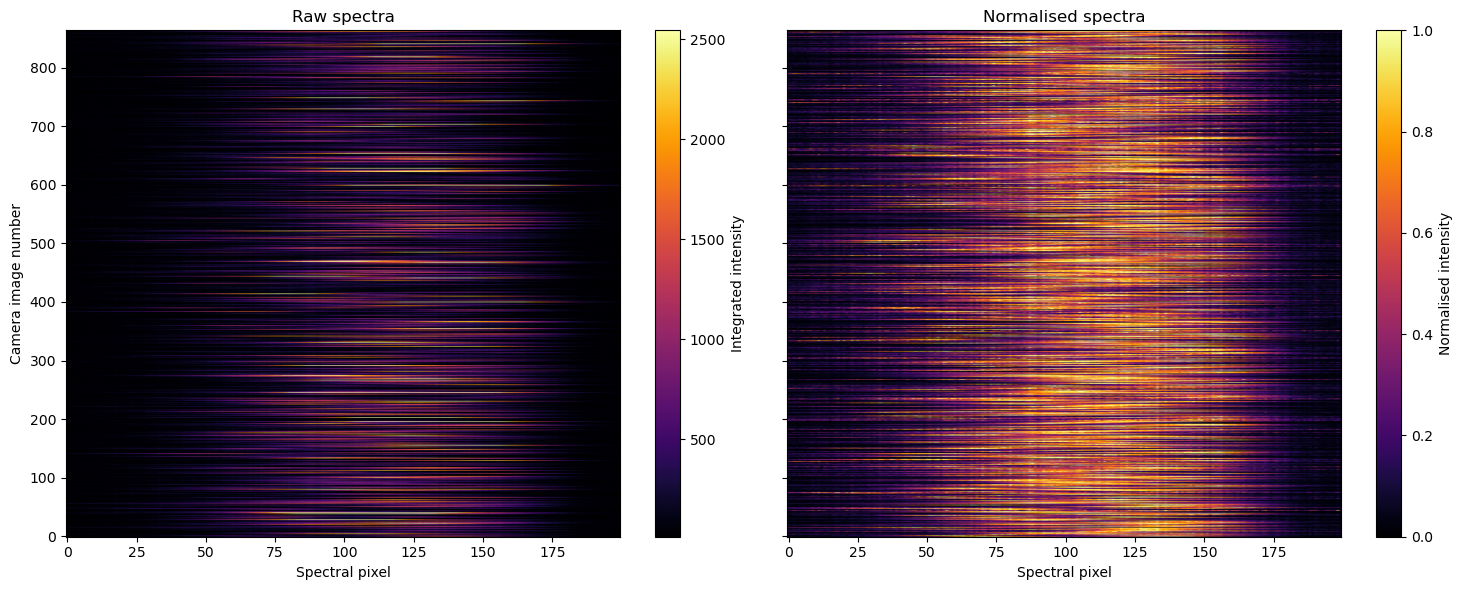

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6),
                        sharey=True)

im = axs[0].imshow(
    spectra_all,
    aspect='auto',
    origin='lower',
    cmap='inferno',
    vmin=np.percentile(spectra_all, 5),
    vmax=np.percentile(spectra_all, 99.5)
)

fig.colorbar(im, ax=axs[0], label='Integrated intensity')

axs[0].set_title('Raw spectra')
axs[0].set_ylabel('Camera image number')

# Normalisation for visual inspection only
maxima = spectra_all.max(axis=1, keepdims=True)

spectra_norm = np.divide(
    spectra_all,
    maxima,
    out=np.zeros_like(spectra_all),
    where=maxima > 0
)

im = axs[1].imshow(
    spectra_norm,
    aspect='auto',
    origin='lower',
    cmap='inferno',
    vmin=0,
    vmax=1
)

fig.colorbar(im, ax=axs[1], label='Normalised intensity')

axs[1].set_title('Normalised spectra')

for ax in axs:
    ax.set_xlabel('Spectral pixel')

fig.tight_layout()
plt.show()

## 6. Single versus multiple resolved spectral peaks
Adapted from `detect_double_peaks_pairscan()` in `inspect_gotthard_double_spikes`. Keep smoothing, height, prominence, width, distance and valley tests, but examine neighbouring peak pairs rather than only the highest-scoring pair. The saved FL23 examples show broad peaks and separations of tens of pixels (e.g. images 81 and 371); the old 17-pixel maximum separation would exclude such pairs. No upper separation cut is used here.

### 6.1 Settings and background correction
The provisional signal ROI is rows 0–399 and the background ROI is rows 450–699. Subtract the per-column background mean multiplied by the signal ROI height. This assumes similar background per spatial pixel in the two ROIs; it is not a measured dark-frame correction. Inspect both ROIs and check for signal leakage or spatially varying detector background. No intensity percentile cut is used. The noise estimate is based on the raw-minus-smoothed residual, not a calibrated camera noise model.

All pixel ranges are half-open; thresholds below are starting values, not measured instrument resolution. Keep the first file for initial tuning, then set `CLASSIFY_ALL_FILES = True` for the run.

In [106]:
CLASSIFY_ALL_FILES = False
SIGNAL_ROI = (0, 400)
BACKGROUND_ROI = (450, 700)
SUBTRACT_BACKGROUND = True

SG_WINDOW = 11                     # odd; compare 7, 9, 15
SG_ORDER = 2
MIN_SIGNAL_SIGMA = 6.0
NOISE_FLOOR = 1.0              # integrated camera units, provisional
EDGE_GUARD = 5

STRICT = dict(min_distance=8, min_width=5, min_height=0.25,
              min_prom_sigma=3.0, min_prom_rel=0.04,
              min_drop=0.08, min_split_sigma=3.0)
RELAXED = dict(min_distance=5, min_width=3, min_height=0.15,
               min_prom_sigma=2.0, min_prom_rel=0.025,
               min_drop=0.04, min_split_sigma=2.0)

In [57]:
# Keep only the integrated spectra and identifiers, not the camera images.
files_to_classify = raw_files if CLASSIFY_ALL_FILES else [RAW_H5]
s0, s1 = SIGNAL_ROI
b0, b1 = BACKGROUND_ROI
assert 0 <= s0 < s1 <= b0 < b1 <= n_spatial

corr_list, bg_list, index_list, file_list, row_list = [], [], [], [], []
for path in files_to_classify:
    with h5py.File(path, 'r') as f:
        if IMAGE_PATH not in f:
            print(path.name, '| No camera data')
            continue
        ds = f[IMAGE_PATH]
        idx = f[INDEX_PATH][:]
        assert ds.shape[1:] == (n_spatial, n_spectral), path.name
        assert len(idx) == len(ds), path.name
        for start in range(0, len(ds), CHUNK_SIZE):
            stop = min(start + CHUNK_SIZE, len(ds))
            chunk = ds[start:stop]
            signal = chunk[:, s0:s1, :].sum(axis=1, dtype=np.float64)
            bg = chunk[:, b0:b1, :].mean(axis=1) * (s1-s0)
            corr_list.append(signal - bg if SUBTRACT_BACKGROUND else signal)
            bg_list.append(bg)
            index_list.append(idx[start:stop])
            file_list.extend([path.name] * (stop-start))
            row_list.extend(range(start, stop))
    print(path.name, '|', len(idx), 'images')

assert corr_list, 'No camera spectra found'
spectra_corr = np.concatenate(corr_list)
spectra_bg = np.concatenate(bg_list)
frame_index = np.concatenate(index_list)
frame_file = np.asarray(file_list)
frame_row = np.asarray(row_list)
print('Corrected spectra:', spectra_corr.shape)
print('Repeated train IDs:', len(frame_index)-len(np.unique(frame_index)))
# Repeated train IDs are reported, not silently removed.

FLASH2_USER1_main_run60609_file1_20261126T154426.1.h5 | 864 images
Corrected spectra: (864, 200)
Repeated train IDs: 0


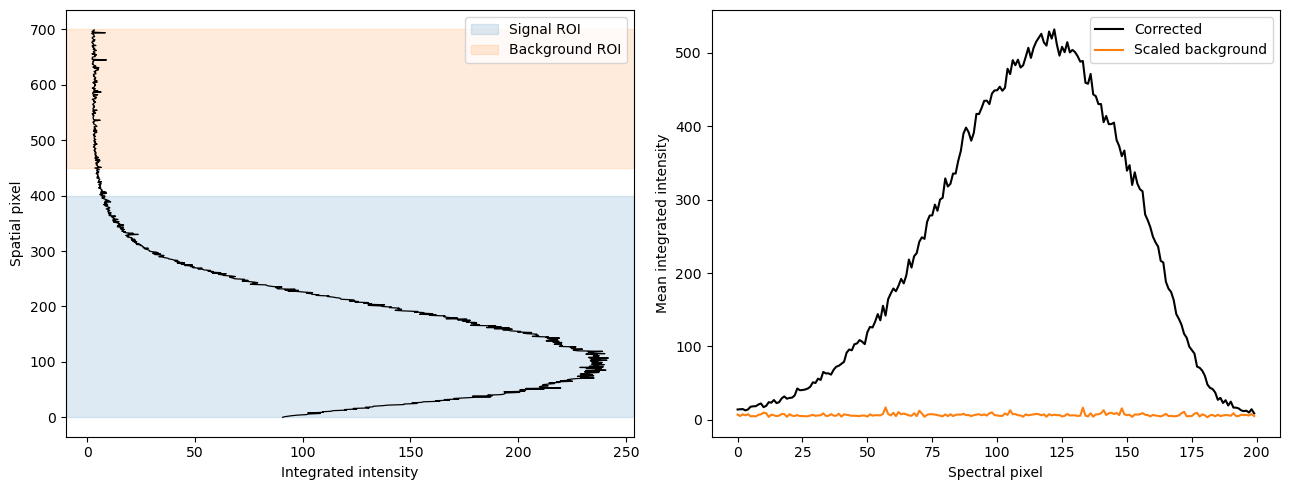

In [58]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
axs[0].plot(spatial_profile, np.arange(n_spatial), color='k', lw=0.9)
axs[0].axhspan(s0, s1, color='C0', alpha=0.15, label='Signal ROI')
axs[0].axhspan(b0, b1, color='C1', alpha=0.15, label='Background ROI')
axs[0].set(xlabel='Integrated intensity', ylabel='Spatial pixel')
axs[0].legend()
axs[1].plot(pixels, spectra_corr.mean(axis=0), color='k', label='Corrected')
axs[1].plot(pixels, spectra_bg.mean(axis=0), color='C1', label='Scaled background')
axs[1].set(xlabel='Spectral pixel', ylabel='Mean integrated intensity')
axs[1].legend()
fig.tight_layout()
plt.show()

### 6.2 Peak detector
For each candidate peak apply the height, prominence, width and distance thresholds. A pair must have **both** a relative valley drop and a valley drop larger than the noise threshold (the old detector used OR). The local residual near the pair also contributes to the noise estimate, since bright spectra can have higher noise than their tails. Use unnormalised, background-corrected spectra; smoothing is only for detection.

A single strict peak with no additional relaxed candidate is called single. Any passing strict pair is enough for the binary multiple class. For exact multiplicity, require every neighbouring strict pair to pass and no extra relaxed candidates (matched within half the strict minimum separation). Otherwise exact multiplicity is ambiguous. Edge-truncated spectra, weak spectra and ambiguous cases are not forced into single or multiple classes. A resolved peak is not necessarily a separate temporal pulse.

In [59]:
def detect_peaks(y, residual, noise, cuts):
    # Candidate peaks and valley tests, adapted from the Gotthard pair scan.
    height = y.max()
    peaks, props = find_peaks(
        y, distance=cuts['min_distance'], width=cuts['min_width'],
        height=cuts['min_height'] * height,
        prominence=max(cuts['min_prom_sigma'] * noise,
                       cuts['min_prom_rel'] * height))

    pairs, margins = [], []
    for p1, p2 in zip(peaks[:-1], peaks[1:]):
        valley = y[p1:p2+1].min()
        weaker = min(y[p1], y[p2])
        drop = weaker - valley
        # Local noise around the two peaks and their valley.
        r = residual[max(0, p1-5):min(len(y), p2+6)]
        local_noise = max(noise, 1.4826*np.median(np.abs(r-np.median(r))))
        margin = min(drop / (weaker*cuts['min_drop']),
                     drop / (local_noise*cuts['min_split_sigma']))
        margins.append(margin)
        if margin >= 1:
            pairs.append((p1, p2))
    return peaks, pairs, np.asarray(margins)


def classify_spectrum(s, strict=STRICT, relaxed=RELAXED, window=SG_WINDOW):
    # Binary and exact classes; 0 = weak, -1 = ambiguous.
    if not np.all(np.isfinite(s)) or not np.any(s):
        return 0, 0, np.array([], int), np.array([], int), [], np.nan, np.nan
    y = savgol_filter(s, window, SG_ORDER)
    residual = s-y
    noise = max(NOISE_FLOOR, 1.4826*np.median(np.abs(residual-np.median(residual))))
    snr = y.max()/noise
    if snr < MIN_SIGNAL_SIGMA:
        return 0, 0, np.array([], int), np.array([], int), [], np.nan, snr

    peaks, pairs, margins = detect_peaks(y, residual, noise, strict)
    rp, relaxed_pairs, _ = detect_peaks(y, residual, noise, relaxed)
    near_edge = (y.argmax() < EDGE_GUARD or y.argmax() >= len(y)-EDGE_GUARD
                 or np.any(peaks < EDGE_GUARD) or np.any(peaks >= len(y)-EDGE_GUARD)
                 or max(y[:EDGE_GUARD].max(), y[-EDGE_GUARD:].max()) >= 0.5*y.max())
    extra = any(not np.any(np.abs(peaks-p) <= strict['min_distance']/2) for p in rp)
    margin = margins[np.argmin(np.abs(margins-1))] if len(margins) else np.nan

    if near_edge:
        binary, exact = -1, -1
    elif pairs:
        binary = 2
        exact = len(peaks) if len(pairs) == len(peaks)-1 and not extra else -1
    elif len(peaks) == 1 and not relaxed_pairs and not extra:
        binary, exact = 1, 1
    elif len(peaks) == 0 and len(rp) == 0:
        binary, exact = 0, 0
    else:
        binary, exact = -1, -1
    return binary, exact, peaks, rp, pairs, margin, snr

In [60]:
# Sanity check with synthetic spectra (not measured FL23 data).
x = np.arange(200)
g = lambda center: 200*np.exp(-0.5*((x-center)/7)**2)
test = [np.zeros_like(x), g(90), g(65)+g(115), g(45)+g(95)+g(145)]
assert [classify_spectrum(s)[1] for s in test] == [0, 1, 2, 3]
print('Clean synthetic checks passed.')

Clean synthetic checks passed.


### 6.3 Classify and count
Report percentages of all recorded camera frames, as well as the conditional fraction among binary-classified frames. A strict multiple may still have ambiguous exact multiplicity. No pulse-level fraction is claimed until the exposure and trigger are verified.

Binary classification (all camera frames):
Single                 485 / 864  ( 56.13%)
Multiple               245 / 864  ( 28.36%)
Weak / noisy            12 / 864  (  1.39%)
Ambiguous              122 / 864  ( 14.12%)

Single among classified:   66.44%
Multiple among classified: 33.56%

Exact multiplicity (all camera frames):
Single                 485 / 864  ( 56.13%)
Double                 209 / 864  ( 24.19%)
Triple                  12 / 864  (  1.39%)
4+                       0 / 864  (  0.00%)
Weak / noisy            12 / 864  (  1.39%)
Ambiguous              146 / 864  ( 16.90%)


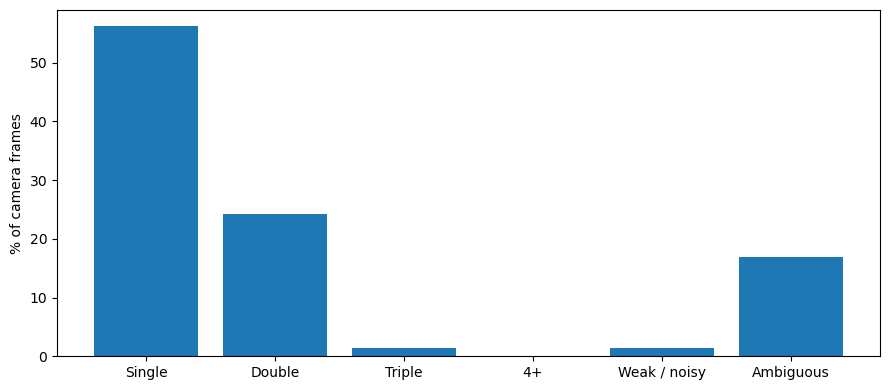

In [74]:
results = [
    classify_spectrum(s, strict=STRICT,
                      relaxed=RELAXED, window=SG_WINDOW)
    for s in spectra_corr
]
binary = np.array([r[0] for r in results])
n_peaks = np.array([r[1] for r in results])
margin = np.array([r[5] for r in results])
peak_snr = np.array([r[6] for r in results])

n = len(binary)
n_classified = np.isin(binary, [1, 2]).sum()
print('Binary classification (all camera frames):')
for name, k in [('Single', 1), ('Multiple', 2), ('Weak / noisy', 0), ('Ambiguous', -1)]:
    count = (binary == k).sum()
    print(f'{name:18s} {count:7,d} / {n:,}  ({100*count/n:6.2f}%)')
if n_classified:
    print(f'\nSingle among classified:   {100*(binary == 1).sum()/n_classified:.2f}%')
    print(f'Multiple among classified: {100*(binary == 2).sum()/n_classified:.2f}%')

print('\nExact multiplicity (all camera frames):')
labels = ['Single', 'Double', 'Triple', '4+', 'Weak / noisy', 'Ambiguous']
counts = [(n_peaks == k).sum() for k in (1, 2, 3)]
counts += [(n_peaks >= 4).sum(), (n_peaks == 0).sum(), (n_peaks == -1).sum()]
assert sum(counts) == n
for name, count in zip(labels, counts):
    print(f'{name:18s} {count:7,d} / {n:,}  ({100*count/n:6.2f}%)')

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, 100*np.asarray(counts)/n)
ax.set_ylabel('% of camera frames')
fig.tight_layout()
plt.show()

### 6.4 Inspect accepted and borderline spectra
Random examples of each main class, plus the nearest strict valley thresholds on either side. Black = corrected spectrum; orange = smoothed spectrum; circles = strict candidate peaks; crosses = relaxed candidates; green segments = passing strict pairs. Near-cut ranking only covers the valley tests, not all other thresholds.

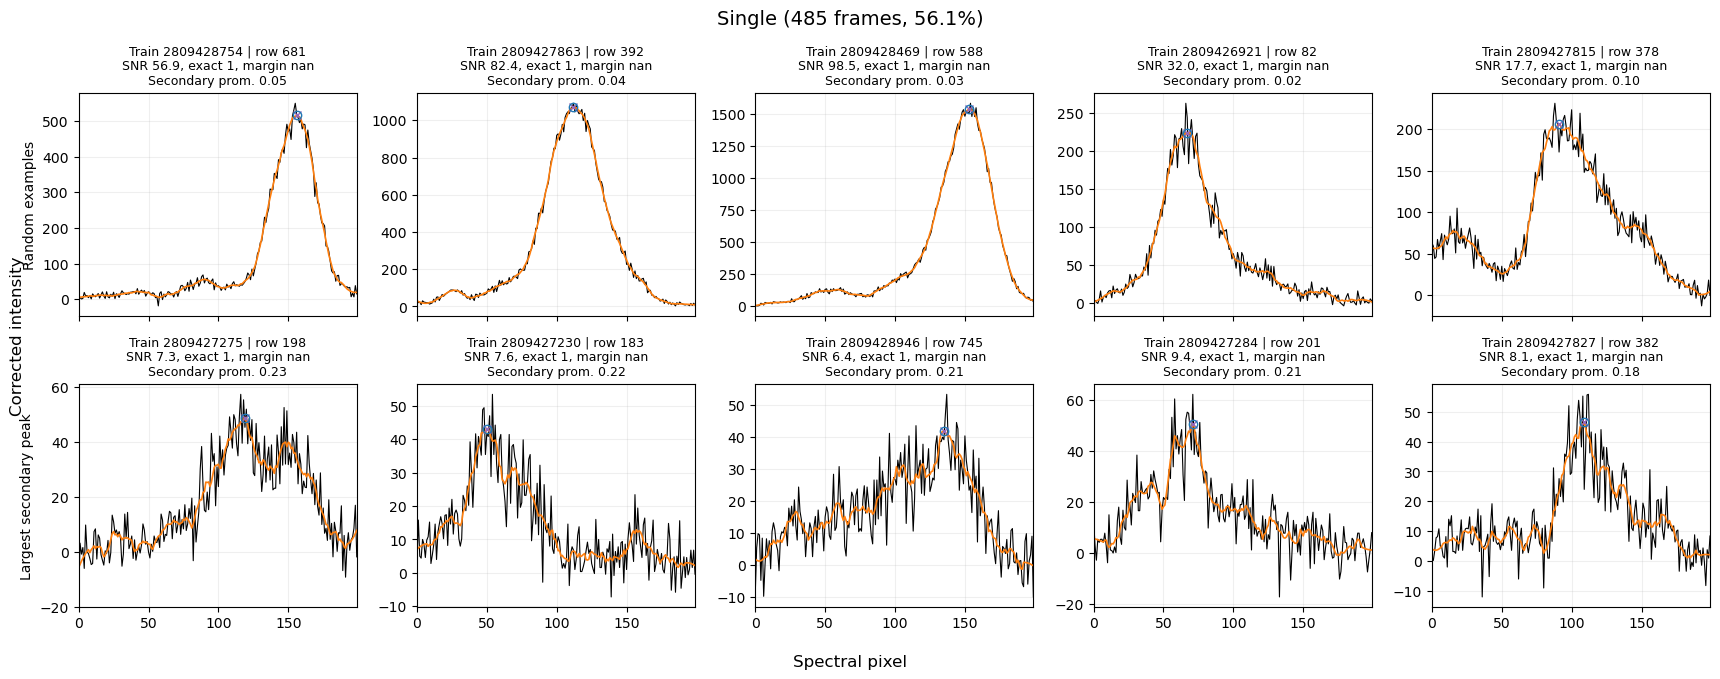

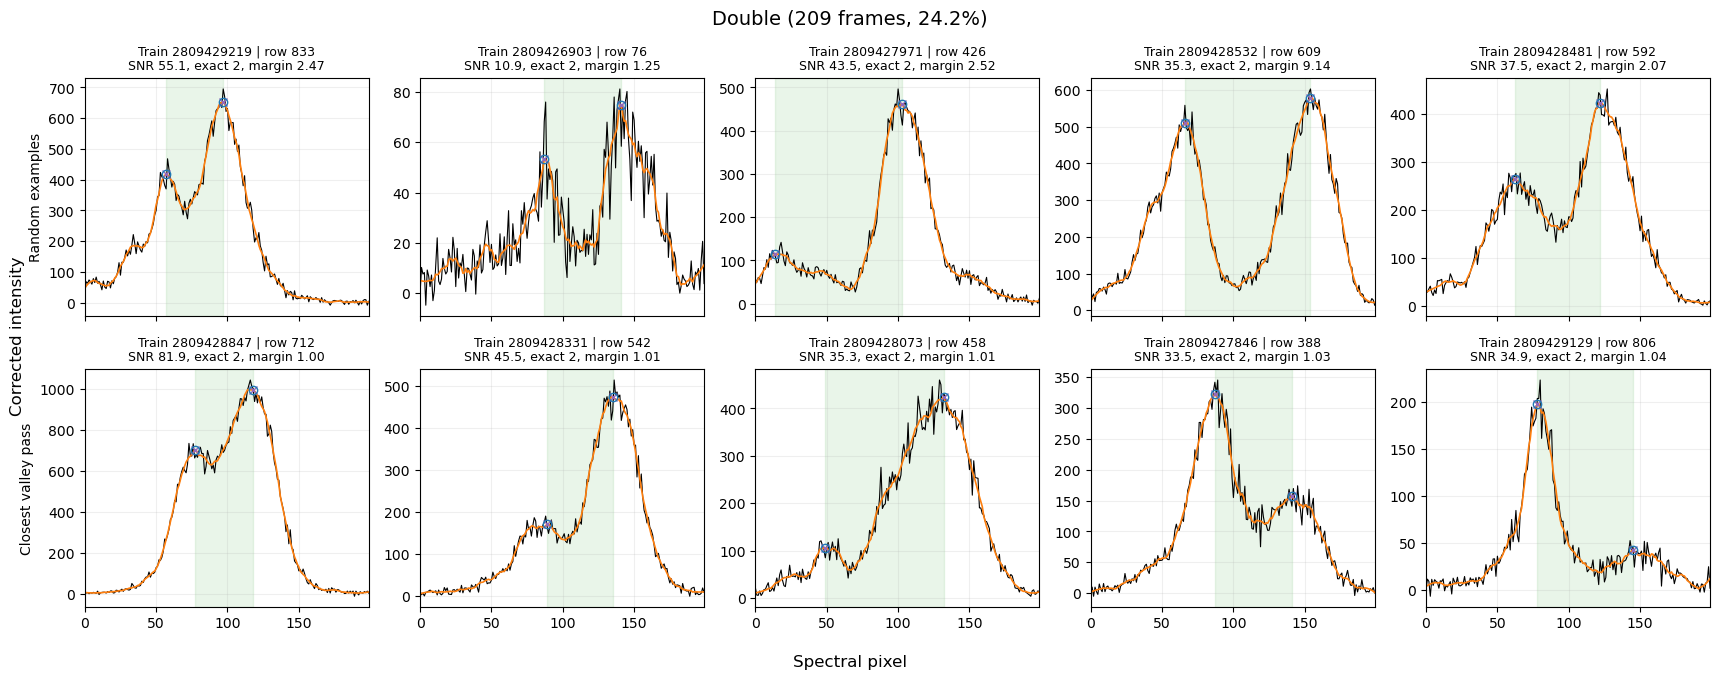

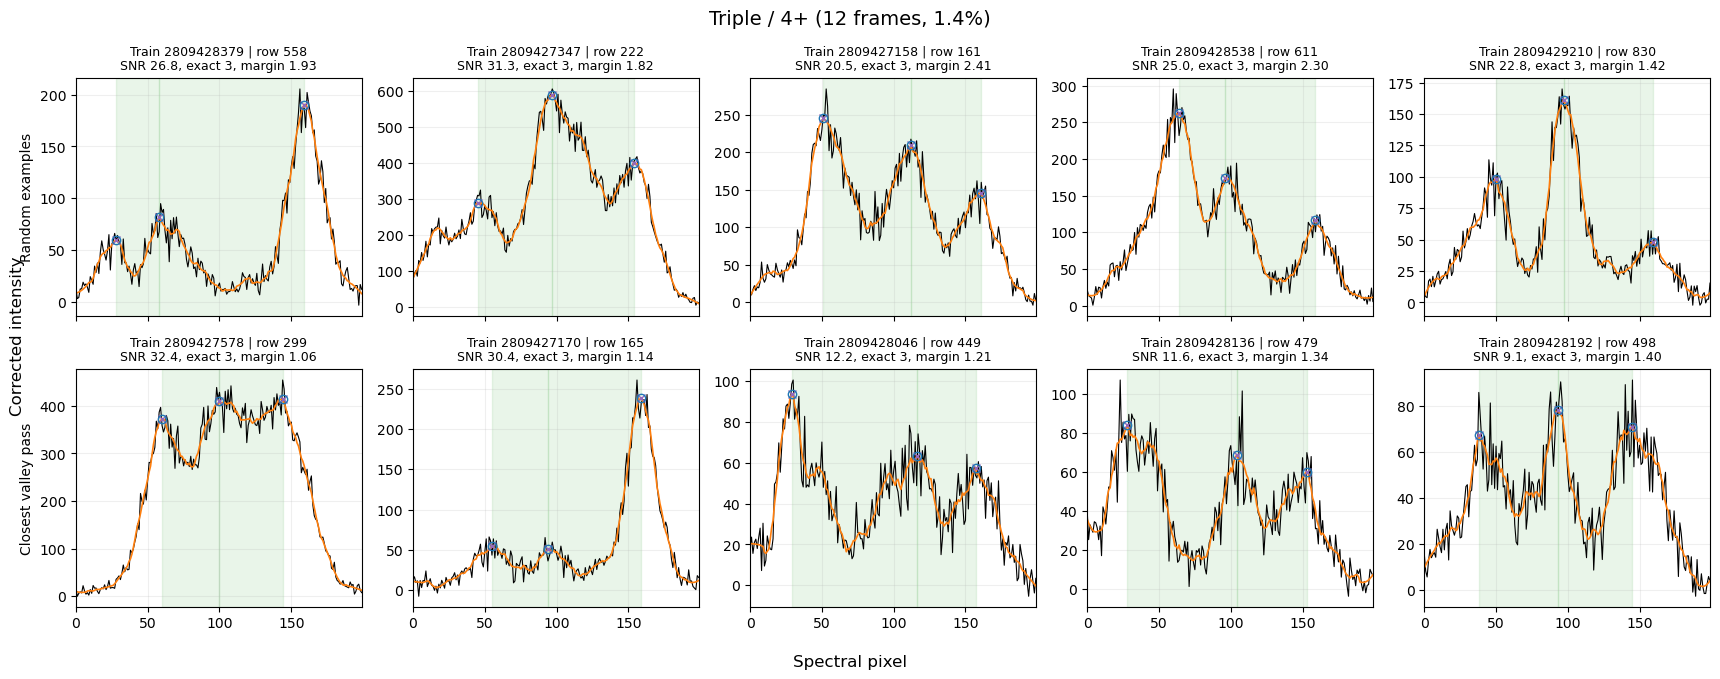

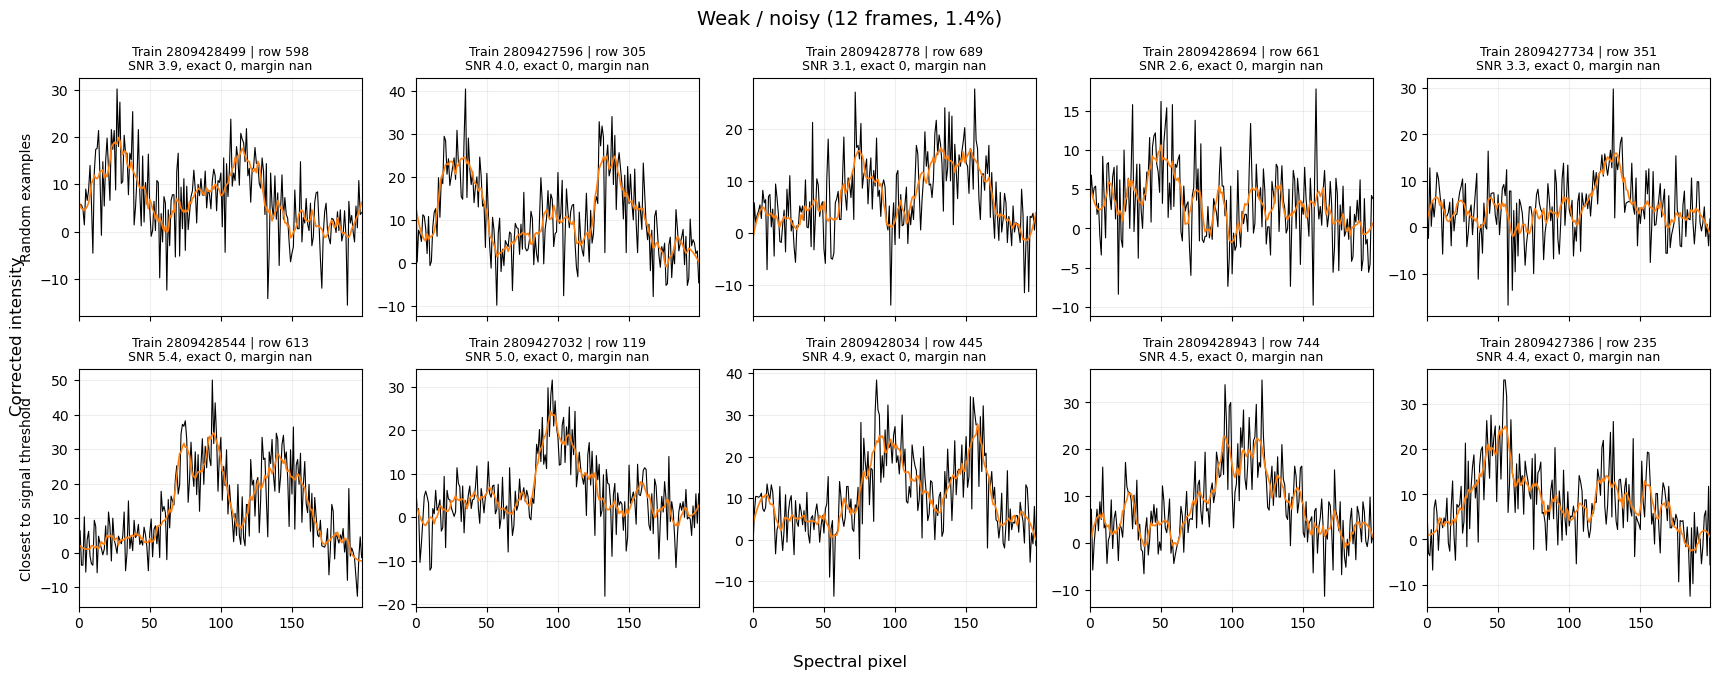

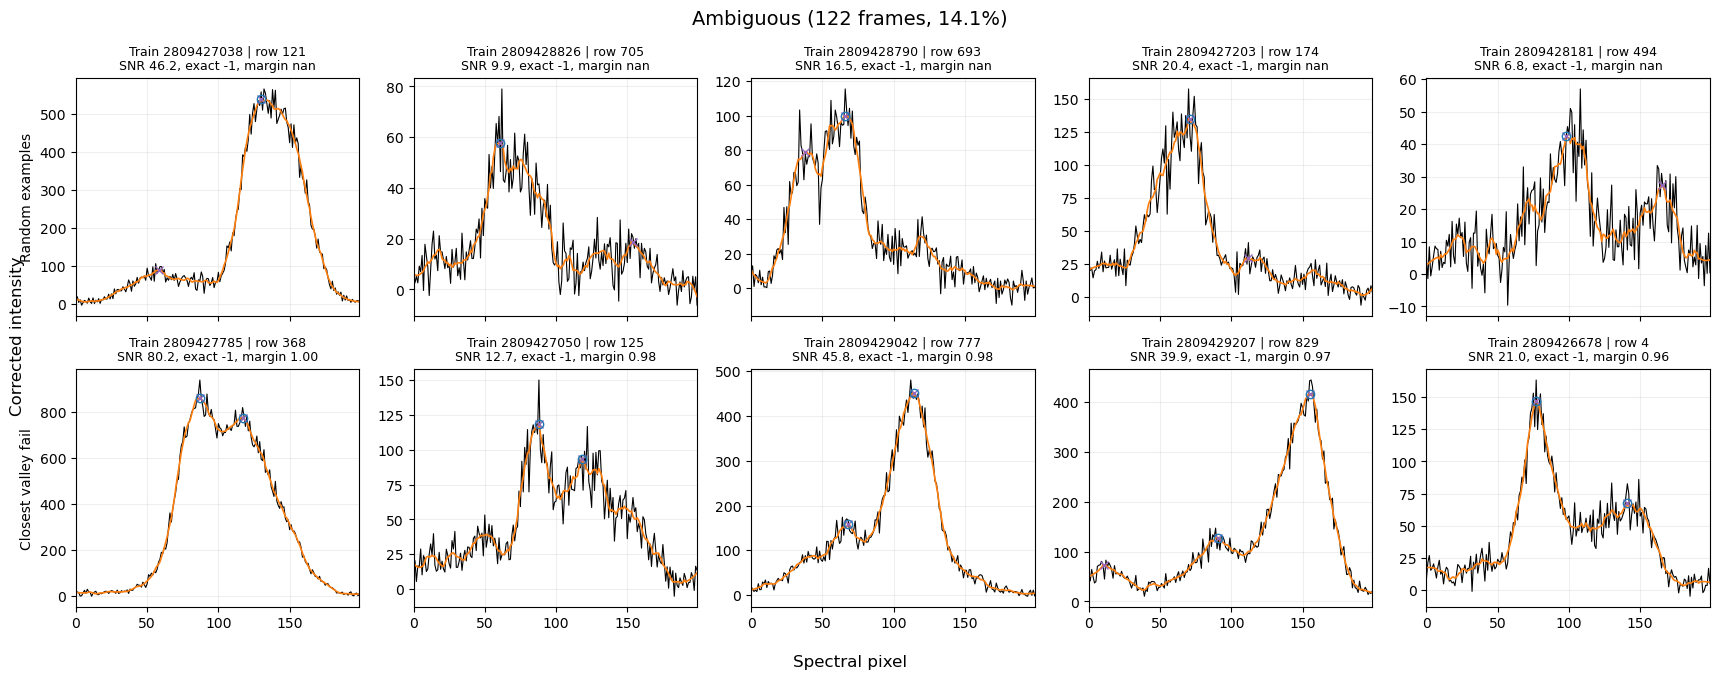

In [62]:
rng = np.random.default_rng(42)
N_PLOT = 5

# Rank accepted singles by the prominence of a possible
# secondary peak, including peaks below the relaxed cuts.
secondary_score = np.full(len(binary), np.nan)
for i in np.flatnonzero(binary == 1):
    y = savgol_filter(spectra_corr[i], SG_WINDOW, SG_ORDER)
    primary = results[i][2][0]
    p, props = find_peaks(
        y,
        distance=RELAXED['min_distance'],
        width=RELAXED['min_width'],
        prominence=0,
    )
    other = np.abs(p - primary) > STRICT['min_distance'] / 2
    secondary_score[i] = 0
    if np.any(other):
        secondary_score[i] = props['prominences'][other].max() / y.max()

# Define the classes
groups = [
    ('Single', np.flatnonzero(binary == 1)),
    ('Double', np.flatnonzero(n_peaks == 2)),
    ('Triple / 4+', np.flatnonzero(n_peaks >= 3)),
    ('Weak / noisy', np.flatnonzero(binary == 0)),
    ('Ambiguous', np.flatnonzero(binary == -1)),
]

for name, ids in groups:
    if not len(ids):
        continue

    # Select borderline examples for the second row
    if name == 'Single':
        borderline = ids[np.argsort(secondary_score[ids])[::-1]]
        second_title = 'Largest secondary peak'
    elif name in ('Double', 'Triple / 4+'):
        valid = ids[np.isfinite(margin[ids]) & (margin[ids] >= 1)]
        borderline = valid[np.argsort(margin[valid] - 1)]
        second_title = 'Closest valley pass'
    elif name == 'Weak / noisy':
        valid = ids[np.isfinite(peak_snr[ids]) & (peak_snr[ids] < MIN_SIGNAL_SIGMA)]
        borderline = valid[np.argsort(MIN_SIGNAL_SIGMA - peak_snr[valid])]
        second_title = 'Closest to signal threshold'
    else:
        valid = ids[np.isfinite(margin[ids]) & (margin[ids] < 1)]
        borderline = valid[np.argsort(1 - margin[valid])]
        second_title = 'Closest valley fail'

    borderline = borderline[:N_PLOT]

    # Random examples, excluding those already selected
    remaining = np.setdiff1d(ids, borderline)
    random_ids = rng.choice(remaining, size=min(N_PLOT, len(remaining)), replace=False)
    selections = [random_ids, borderline]

    fig, axs = plt.subplots(
        2, N_PLOT,
        figsize=(3.5 * N_PLOT, 6.8),
        sharex=True,
        squeeze=False,
    )

    for row, selected in enumerate(selections):
        for ax in axs[row]:
            ax.set_visible(False)

        for ax, i in zip(axs[row], selected):
            ax.set_visible(True)
            s = spectra_corr[i]
            y = savgol_filter(s, SG_WINDOW, SG_ORDER)
            _, exact, p, rp, pairs, m, snr = results[i]

            ax.plot(pixels, s, color='k', lw=0.8)
            ax.plot(pixels, y, color='C1', lw=1.2)
            ax.plot(rp, y[rp], 'x', color='C4')
            ax.plot(p, y[p], 'o', mfc='none', color='C0')

            for p1, p2 in pairs:
                ax.axvspan(p1, p2, color='C2', alpha=0.10)

            title = (
                f'Train {frame_index[i]} | row {frame_row[i]}\n'
                f'SNR {snr:.1f}, exact {exact}, margin {m:.2f}'
            )
            if name == 'Single':
                title += f'\nSecondary prom. {secondary_score[i]:.2f}'

            ax.set_title(title, fontsize=9)
            ax.set_xlim(0, n_spectral - 1)
            ax.grid(alpha=0.2)

    fig.suptitle(
        f'{name} ({len(ids):,} frames, {100 * len(ids) / len(binary):.1f}%)',
        fontsize=14,
    )
    axs[0, 0].set_ylabel('Random examples')
    axs[1, 0].set_ylabel(second_title)
    fig.supxlabel('Spectral pixel')
    fig.supylabel('Corrected intensity')
    fig.tight_layout()
    plt.show()

### Second opportunity: gaussian fitting   

In [75]:
from scipy.optimize import least_squares

MIN_SIGMA = 5 / 2.355        # Minimum Gaussian FWHM = 5 pixels
MAX_SIGMA = 60               # Maximum Gaussian sigma, pixels

MIN_COMPONENT_RATIO = 0.15
MIN_DELTA_BIC = 3

MAX_RESID_RMS = 2.0          # Relative to estimated noise
MAX_RESID_SMOOTH = 4.0


def gaussian_model(x, baseline, *pars):
    y = np.full_like(x, baseline, dtype=float)
    for amp, centre, sigma in np.asarray(pars).reshape(-1, 3):
        y += amp * np.exp(-0.5 * ((x - centre) / sigma) ** 2)
    return y


def fit_gaussians(s, k, previous=None):
    x = np.arange(len(s), dtype=float)
    y = savgol_filter(s, SG_WINDOW, SG_ORDER)

    baseline = np.percentile(y, 10)
    height = max(y.max() - baseline, 1.0)

    # Possible starting peak positions
    p, props = find_peaks(y, distance=5, prominence=0)
    p = p[np.argsort(props['prominences'])[::-1]]

    # Alternative starting positions across the spectrum
    w = np.clip(y - baseline, 0, None)
    if w.sum() == 0:
        return None

    quantiles = np.interp((np.arange(k) + 0.5) / k, np.cumsum(w) / w.sum(), x)
    seeds = [
        quantiles,
        y.argmax() + 18 * (np.arange(k) - (k - 1) / 2),
    ]
    if len(p) >= k:
        seeds.append(p[:k])

    # Try adding a Gaussian where the previous model underestimated the measured spectrum
    if previous is not None:
        r = savgol_filter(s - previous['fit'], SG_WINDOW, SG_ORDER)
        seeds.append(np.r_[previous['pars'][1::3], r.argmax()])

    # Bounds: positive amplitudes, centres inside the detector, physically reasonable widths
    lower = [-np.inf] + [0, 0, MIN_SIGMA] * k
    upper = [np.inf] + [3 * height, x[-1], MAX_SIGMA] * k

    best = None
    for centres in seeds:
        centres = np.clip(centres, 0, x[-1])
        for sigma in (8.0, 20.0):
            amps = np.clip(np.interp(centres, x, y) - baseline, 0.1 * height, height)
            p0 = np.r_[
                baseline,
                np.column_stack([amps, centres, np.full(k, sigma)]).ravel(),
            ]
            res = least_squares(
                lambda pars: gaussian_model(x, *pars) - s,
                p0,
                bounds=(lower, upper),
                x_scale='jac',
                max_nfev=1500,
            )
            if not res.success:
                continue

            rss = np.sum(res.fun ** 2)
            # BIC: lower is better
            bic = len(s) * np.log(max(rss / len(s), 1e-300)) + len(res.x) * np.log(len(s))

            if best is None or bic < best['bic']:
                best = dict(
                    k=k,
                    pars=res.x[1:],
                    baseline=res.x[0],
                    fit=gaussian_model(x, *res.x),
                    bic=bic,
                    rms=np.sqrt(rss / len(s)),
                )

    return best

In [76]:
ambiguous_ids = np.flatnonzero(binary == -1)

# Keep the original classification unchanged
binary_after = binary.copy()
n_peaks_after = n_peaks.copy()

gaussian_results = {}

print(f'Fitting {len(ambiguous_ids):,} ambiguous spectra')

for j, i in enumerate(ambiguous_ids):
    s = spectra_corr[i]
    y = savgol_filter(s, SG_WINDOW, SG_ORDER)

    residual = s - y
    noise = max(NOISE_FLOOR, 1.4826 * np.median(np.abs(residual - np.median(residual))))

    # Do not recover spectra truncated by the detector edge
    p = results[i][2]

    near_edge = (
        y.argmax() < EDGE_GUARD
        or y.argmax() >= len(y) - EDGE_GUARD
        or np.any(p < EDGE_GUARD)
        or np.any(p >= len(y) - EDGE_GUARD)
        or max(y[:EDGE_GUARD].max(), y[-EDGE_GUARD:].max()) >= 0.5 * y.max()
    )

    if near_edge:
        gaussian_results[i] = dict(reason='Edge / truncated')
        continue

    # Fit one, two and three Gaussians
    fits = []
    previous = None

    for k in (1, 2, 3):
        fit = fit_gaussians(s, k, previous)
        fits.append(fit)
        previous = fit

    if any(f is None for f in fits):
        gaussian_results[i] = dict(reason='Fit failed')
        continue

    # Select the model with the lowest BIC
    order = np.argsort([f['bic'] for f in fits])
    best = fits[order[0]]
    delta_bic = fits[order[1]]['bic'] - best['bic']

    k = best['k']
    components = best['pars'].reshape(-1, 3)

    amps = components[:, 0]
    centres = np.sort(components[:, 1])
    sigmas = components[:, 2]

    # Check fit residuals
    fit_residual = s - best['fit']
    rms_sigma = best['rms'] / noise
    smooth_residual = savgol_filter(fit_residual, SG_WINDOW, SG_ORDER)
    max_residual = np.max(np.abs(smooth_residual)) / noise

    reason = 'Accepted'

    if delta_bic < MIN_DELTA_BIC:
        reason = 'BIC inconclusive'
    elif rms_sigma > MAX_RESID_RMS:
        reason = 'Large fit residual'
    elif max_residual > MAX_RESID_SMOOTH:
        reason = 'Structured fit residual'
    elif np.any(amps < MIN_COMPONENT_RATIO * amps.max()):
        reason = 'Small Gaussian component'
    elif np.any(amps < 3 * noise):
        reason = 'Component below noise'
    elif np.any(sigmas <= 1.01 * MIN_SIGMA):
        reason = 'Width at lower bound'
    elif np.any(sigmas >= 0.99 * MAX_SIGMA):
        reason = 'Width at upper bound'
    elif np.any(np.diff(centres) < STRICT['min_distance']):
        reason = 'Components too close'

    # Check whether the fitted components actually
    # produce distinct, resolved spectral peaks
    model_signal = best['fit'] - best['baseline']
    fitted_peaks, _ = find_peaks(model_signal, distance=STRICT['min_distance'])

    if reason == 'Accepted':
        if len(fitted_peaks) != k:
            reason = 'Unresolved Gaussian components'
        else:
            for p1, p2 in zip(fitted_peaks[:-1], fitted_peaks[1:]):
                weaker = min(model_signal[p1], model_signal[p2])
                valley = model_signal[p1:p2 + 1].min()
                drop = weaker - valley

                if (
                    drop < STRICT['min_drop'] * weaker
                    or drop < STRICT['min_split_sigma'] * noise
                ):
                    reason = 'Fitted valley too shallow'
                    break

    gaussian_results[i] = dict(
        fits=fits,
        best=best,
        delta_bic=delta_bic,
        noise=noise,
        rms_sigma=rms_sigma,
        max_residual=max_residual,
        reason=reason,
    )

    if reason == 'Accepted':
        n_peaks_after[i] = k
        binary_after[i] = 1 if k == 1 else 2

    if (j + 1) % 50 == 0:
        print(f'{j + 1:,} / {len(ambiguous_ids):,}')

print('Gaussian fitting finished')

Fitting 122 ambiguous spectra
50 / 122
100 / 122
Gaussian fitting finished


Class                  Before      After    Change (pp)
--------------------------------------------------------
Single                 56.13%     63.08%         +6.94
Multiple               28.36%     28.70%         +0.35
Ambiguous              14.12%      6.83%         -7.29
Weak / noisy            1.39%      1.39%         +0.00

Originally ambiguous spectra:
Recovered single           60
Recovered double            3
Recovered triple            0
Still ambiguous            59


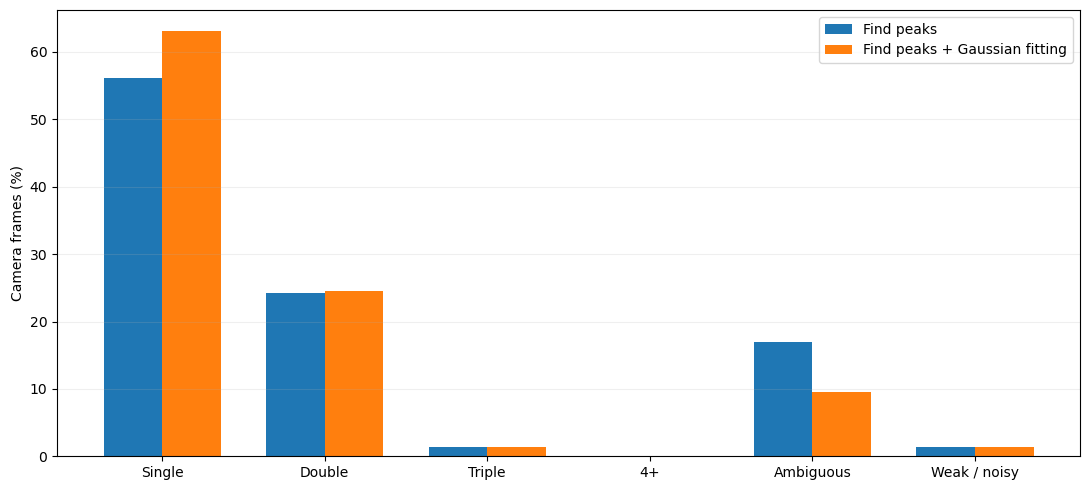

In [102]:
groups = [
    ('Single', 1),
    ('Multiple', 2),
    ('Ambiguous', -1),
    ('Weak / noisy', 0)
]

print(f'{"Class":18s} {"Before":>10s} {"After":>10s} {"Change (pp)":>14s}')
print('-' * 56)

for name, k in groups:
    before = 100 * np.mean(binary == k)
    after = 100 * np.mean(binary_after == k)
    print(f'{name:18s} {before:9.2f}% {after:9.2f}% {after - before:+13.2f}')

print('\nOriginally ambiguous spectra:')

for k, name in [
    (1, 'Recovered single'),
    (2, 'Recovered double'),
    (3, 'Recovered triple'),
    (-1, 'Still ambiguous')
]:
    count = np.sum(n_peaks_after[ambiguous_ids] == k)
    print(f'{name:22s} {count:6d}')

# Comparison figure
labels = ['Single', 'Double', 'Triple', '4+', 'Ambiguous', 'Weak / noisy']
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(11, 5))

for values, offset, label in [
    (n_peaks, -0.18, 'Find peaks'),
    (n_peaks_after, 0.18, 'Find peaks + Gaussian fitting')
]:
    counts = [
        np.sum(values == 1),
        np.sum(values == 2),
        np.sum(values == 3),
        np.sum(values >= 4),
        np.sum(values == -1),
        np.sum(values == 0)
    ]
    ax.bar(x + offset, 100 * np.asarray(counts) / len(values), width=0.36, label=label)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Camera frames (%)')
ax.legend()
ax.grid(axis='y', alpha=0.2)

fig.tight_layout()
plt.show()

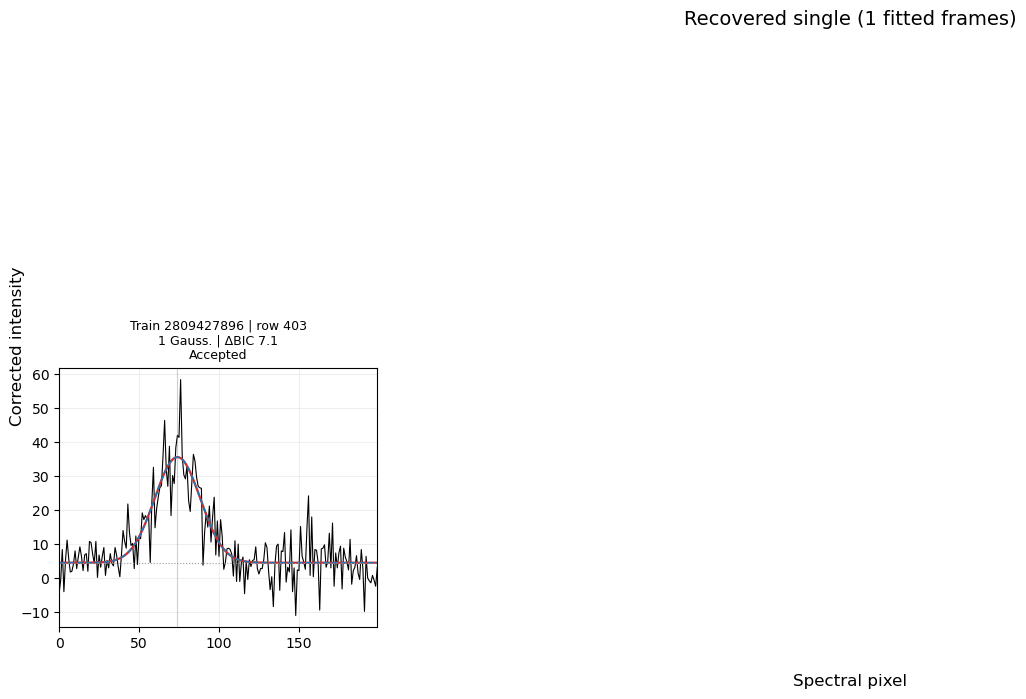

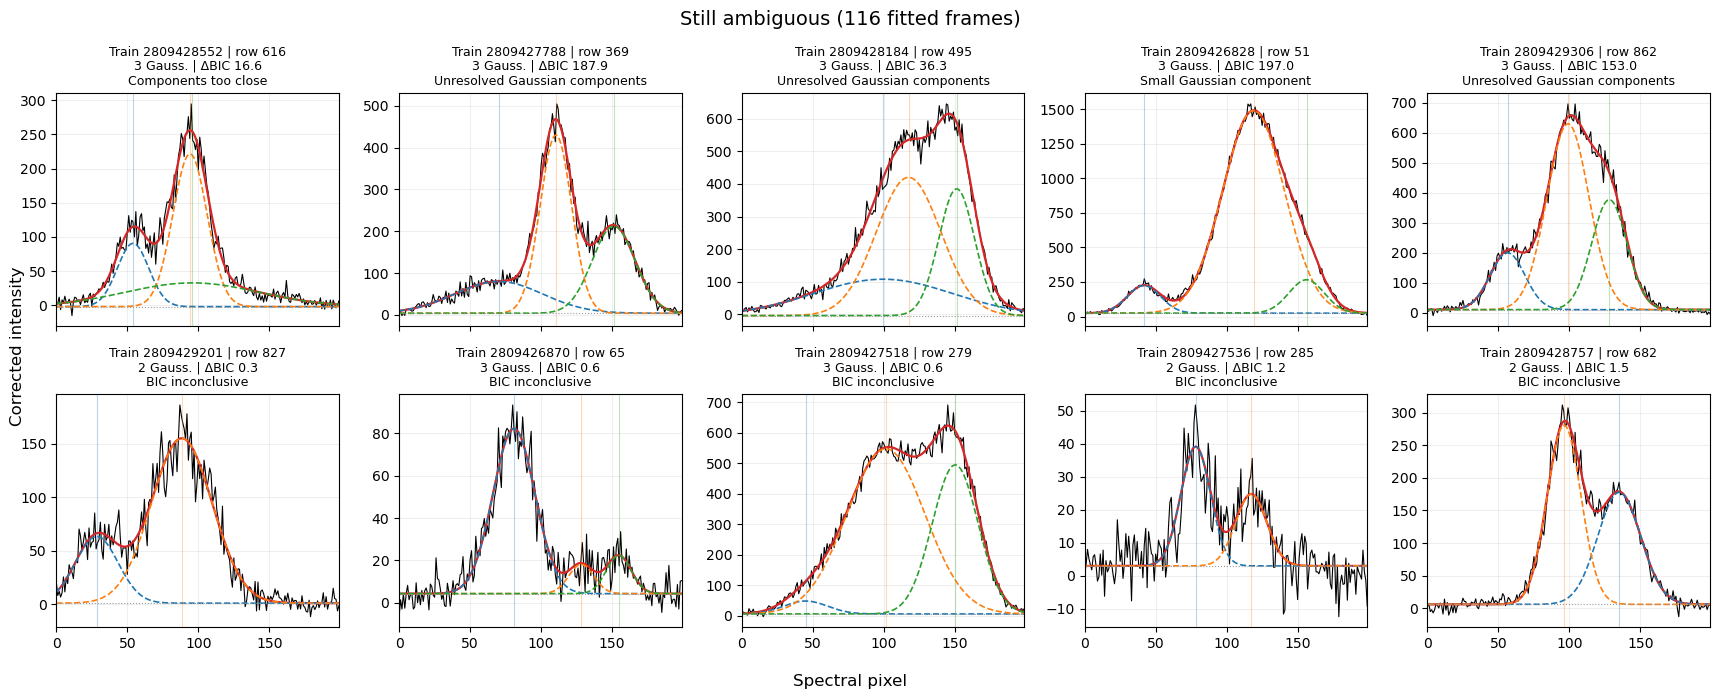

In [78]:
rng = np.random.default_rng(42)
N_PLOT = 5

groups = [
    ('Recovered single', 1),
    ('Recovered double', 2),
    ('Recovered triple', 3),
    ('Still ambiguous', -1)
]

for name, k in groups:

    ids = ambiguous_ids[n_peaks_after[ambiguous_ids] == k]

    # Only spectra for which fitting was successful
    ids = np.array([
        i for i in ids
        if 'best' in gaussian_results[i]
    ], dtype=int)

    if not len(ids):
        continue

    delta = np.array([
        gaussian_results[i]['delta_bic']
        for i in ids
    ])

    borderline = ids[np.argsort(delta)[:N_PLOT]]

    remaining = np.setdiff1d(ids, borderline)

    random_ids = rng.choice(
        remaining,
        size=min(N_PLOT, len(remaining)),
        replace=False
    )

    fig, axs = plt.subplots(
        2, N_PLOT,
        figsize=(17.5, 7),
        sharex=True,
        squeeze=False
    )

    for ax in axs.flat:
        ax.set_visible(False)

    for row, selected in enumerate([random_ids, borderline]):

        for ax, i in zip(axs[row], selected):

            ax.set_visible(True)

            info = gaussian_results[i]
            best = info['best']

            s = spectra_corr[i]

            # Measured spectrum
            ax.plot(pixels, s, color='k', lw=0.8,
                    label='Measured')

            # Total Gaussian fit
            ax.plot(pixels, best['fit'],
                    color='C3', lw=1.6,
                    label='Total fit')

            # Individual Gaussian components
            for j, (amp, centre, sigma) in enumerate(
                best['pars'].reshape(-1, 3)
            ):

                component = amp*np.exp(
                    -0.5*((pixels-centre)/sigma)**2
                )

                ax.plot(
                    pixels,
                    component+best['baseline'],
                    '--', color=f'C{j}',
                    lw=1.2
                )

                ax.axvline(
                    centre, color=f'C{j}',
                    alpha=0.3, lw=0.8
                )

            ax.axhline(best['baseline'],
                       color='0.6', ls=':', lw=0.8)

            ax.set_title(
                f'Train {frame_index[i]} | row {frame_row[i]}\n'
                f'{best["k"]} Gauss. | ΔBIC {info["delta_bic"]:.1f}\n'
                f'{info["reason"]}',
                fontsize=9
            )

            ax.set_xlim(0, n_spectral-1)
            ax.grid(alpha=0.2)

    fig.suptitle(f'{name} ({len(ids)} fitted frames)',
                 fontsize=14)

    fig.supxlabel('Spectral pixel')
    fig.supylabel('Corrected intensity')

    fig.tight_layout()
    plt.show()

Gaussian fitting result                Count   Fraction
----------------------------------------------------------
Unresolved Gaussian components            47     38.52%
Small Gaussian component                  23     18.85%
Component below noise                     13     10.66%
Fitted valley too shallow                 11      9.02%
Components too close                      11      9.02%
BIC inconclusive                           8      6.56%
Edge / truncated                           5      4.10%
Large fit residual                         2      1.64%
Accepted                                   1      0.82%
Width at upper bound                       1      0.82%


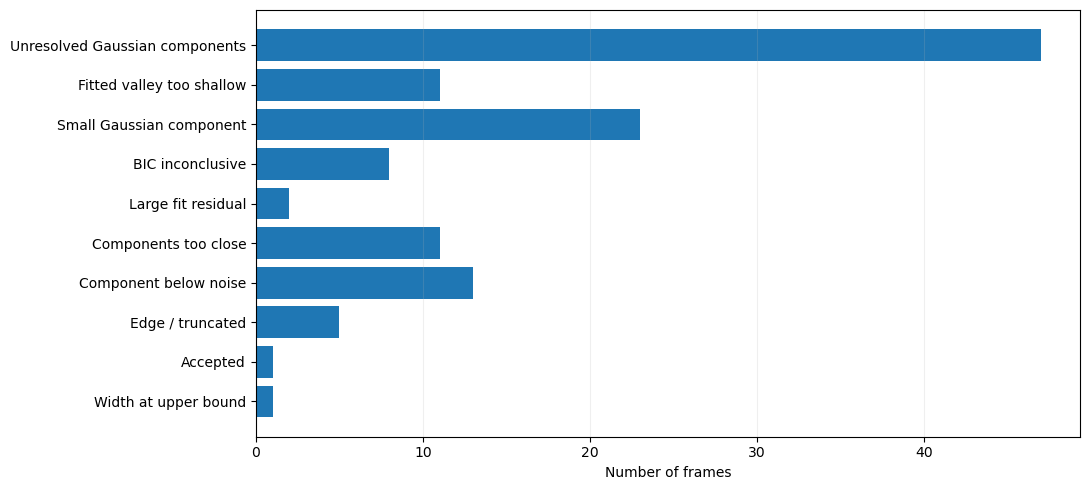

In [79]:
reasons = {}

for i in ambiguous_ids:

    reason = gaussian_results[i]['reason']

    reasons[reason] = reasons.get(reason, 0) + 1


print(f'{"Gaussian fitting result":35s} '
      f'{"Count":>8s} {"Fraction":>10s}')

print('-'*58)

for reason, count in sorted(
    reasons.items(),
    key=lambda item: -item[1]
):

    print(f'{reason:35s} {count:8d} '
          f'{100*count/len(ambiguous_ids):9.2f}%')


if reasons:

    fig, ax = plt.subplots(figsize=(11, 5))

    ax.barh(list(reasons), list(reasons.values()))

    ax.invert_yaxis()
    ax.set_xlabel('Number of frames')
    ax.grid(axis='x', alpha=0.2)

    fig.tight_layout()
    plt.show()

In [82]:
BIC_RANGE = 10

binary_after = binary.copy()
n_peaks_after = n_peaks.copy()

gaussian_binary_results = {}

for i in ambiguous_ids:

    info = gaussian_results[i]

    if 'fits' not in info:
        gaussian_binary_results[i] = info['reason']
        continue

    s = spectra_corr[i]
    noise = info['noise']

    fits = info['fits']
    best_bic = min(f['bic'] for f in fits)

    # Models that are competitive according to BIC
    good_fits = [
        f for f in fits
        if f['bic'] - best_bic <= BIC_RANGE
    ]

    model_classes = []
    model_counts = []

    for fit in good_fits:

        # Total fitted curve, without constant baseline
        y = fit['fit'] - fit['baseline']

        residual = s - fit['fit']

        rms_sigma = np.sqrt(np.mean(residual**2)) / noise

        smooth_residual = savgol_filter(
            residual, SG_WINDOW, SG_ORDER
        )

        max_residual = np.max(
            np.abs(smooth_residual)
        ) / noise

        # Reject poor fits
        if (rms_sigma > MAX_RESID_RMS
                or max_residual > MAX_RESID_SMOOTH):

            model_classes.append(-1)
            model_counts.append(-1)
            continue

        # Apply the existing peak detector to the total fit
        p, pairs, _ = detect_peaks(
            y, residual, noise, STRICT
        )

        rp, relaxed_pairs, _ = detect_peaks(
            y, residual, noise, RELAXED
        )

        extra = any(
            not np.any(np.abs(p-q) <= STRICT['min_distance']/2)
            for q in rp
        )

        near_edge = (
            y.argmax() < EDGE_GUARD
            or y.argmax() >= len(y)-EDGE_GUARD
            or np.any(p < EDGE_GUARD)
            or np.any(p >= len(y)-EDGE_GUARD)
            or max(y[:EDGE_GUARD].max(),
                   y[-EDGE_GUARD:].max()) >= 0.5*y.max()
        )

        if near_edge:

            model_classes.append(-1)
            model_counts.append(-1)

        elif pairs:

            # At least two resolved peaks
            model_classes.append(2)

            if len(pairs) == len(p)-1 and not extra:
                model_counts.append(len(p))
            else:
                model_counts.append(-1)

        elif len(p) == 1 and not relaxed_pairs and not extra:

            model_classes.append(1)
            model_counts.append(1)

        else:

            model_classes.append(-1)
            model_counts.append(-1)

    # Require agreement between competitive models
    if all(k == 2 for k in model_classes):

        binary_after[i] = 2
        gaussian_binary_results[i] = 'Recovered multiple'

        # Exact multiplicity only if all models agree
        if len(set(model_counts)) == 1:
            n_peaks_after[i] = model_counts[0]

    elif all(k == 1 for k in model_classes):

        binary_after[i] = 1
        n_peaks_after[i] = 1

        gaussian_binary_results[i] = 'Recovered single'

    else:

        gaussian_binary_results[i] = 'Still ambiguous'


print('Binary Gaussian classification finished')

Binary Gaussian classification finished


In [101]:
print(f'{"Class":18s} {"Before":>10s} '
      f'{"After":>10s} {"Change (pp)":>14s}')

print('-'*56)

for name, k in [
    ('Single', 1),
    ('Multiple', 2),
    ('Ambiguous', -1),
    ('Weak / noisy', 0)
]:

    before = 100*np.mean(binary == k)
    after = 100*np.mean(binary_after == k)

    print(f'{name:18s} {before:9.2f}% '
          f'{after:9.2f}% {after-before:+13.2f}')


print('\nOriginally ambiguous spectra:')

for name, k in [
    ('Recovered single', 1),
    ('Recovered multiple', 2),
    ('Still ambiguous', -1)
]:

    count = np.sum(binary_after[ambiguous_ids] == k)

    print(f'{name:22s} {count:6d}')


print('\nMultiple spikes with uncertain exact multiplicity:')

print('Before:', np.sum((binary == 2) & (n_peaks == -1)))

print('After: ', np.sum(
    (binary_after == 2) & (n_peaks_after == -1)
))

Class                  Before      After    Change (pp)
--------------------------------------------------------
Single                 56.13%     63.08%         +6.94
Multiple               28.36%     28.70%         +0.35
Ambiguous              14.12%      6.83%         -7.29
Weak / noisy            1.39%      1.39%         +0.00

Originally ambiguous spectra:
Recovered single           60
Recovered multiple          3
Still ambiguous            59

Multiple spikes with uncertain exact multiplicity:
Before: 24
After:  24


Recovered multiple-spike spectra: 3


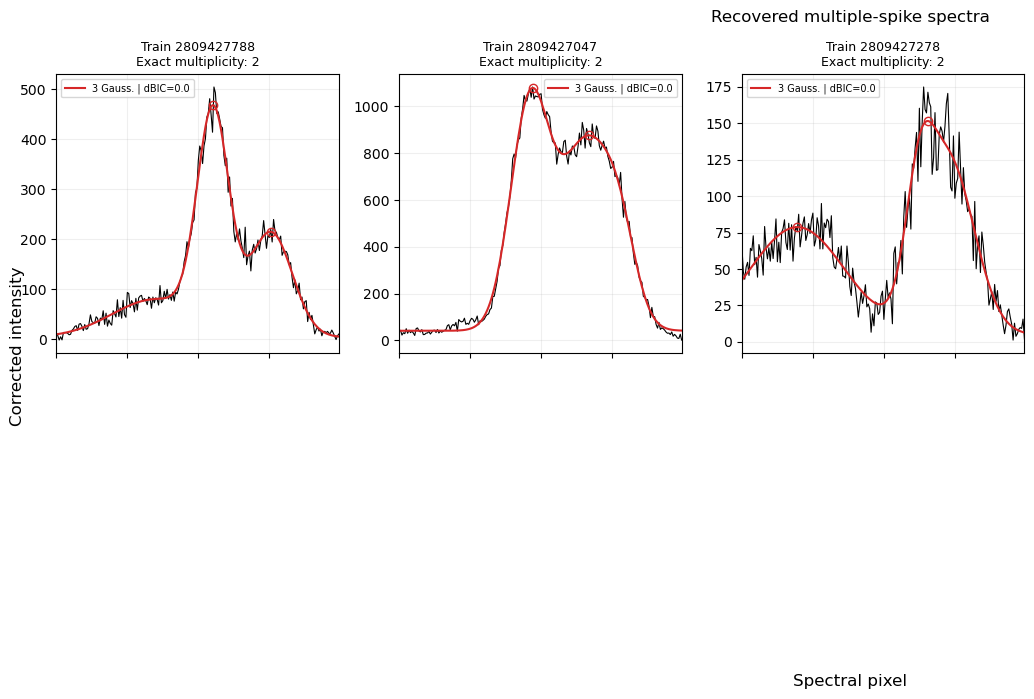

In [84]:
rng = np.random.default_rng(42)

ids = np.flatnonzero(
    (binary == -1) & (binary_after == 2)
)

print(f'Recovered multiple-spike spectra: {len(ids)}')

if len(ids):

    selected = rng.choice(
        ids, min(10, len(ids)), replace=False
    )

    fig, axs = plt.subplots(
        2, 5, figsize=(17.5, 7),
        sharex=True, squeeze=False
    )

    for ax in axs.flat:
        ax.set_visible(False)

    for ax, i in zip(axs.flat, selected):

        ax.set_visible(True)

        info = gaussian_results[i]

        best_bic = min(f['bic'] for f in info['fits'])

        ax.plot(pixels, spectra_corr[i],
                color='k', lw=0.8)

        for fit in info['fits']:

            delta = fit['bic'] - best_bic

            if delta > BIC_RANGE:
                continue

            ax.plot(
                pixels, fit['fit'],
                color=f'C{fit["k"]}',
                lw=1.5,
                label=f'{fit["k"]} Gauss. | dBIC={delta:.1f}'
            )

            p, pairs, _ = detect_peaks(
                fit['fit'] - fit['baseline'],
                spectra_corr[i] - fit['fit'],
                info['noise'],
                STRICT
            )

            ax.plot(
                p, fit['fit'][p], 'o',
                color=f'C{fit["k"]}', mfc='none'
            )

        ax.set_title(
            f'Train {frame_index[i]}\n'
            f'Exact multiplicity: {n_peaks_after[i]}',
            fontsize=9
        )

        ax.set_xlim(0, n_spectral-1)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.2)

    fig.suptitle('Recovered multiple-spike spectra')
    fig.supxlabel('Spectral pixel')
    fig.supylabel('Corrected intensity')

    fig.tight_layout()
    plt.show()

In [86]:
recovered_single_ids = np.flatnonzero(
    (binary == -1) & (binary_after == 1)
)

print(f'Recovered single-spike spectra: {len(recovered_single_ids)}')

single_vs_multi_dbic = np.full(len(binary), np.nan)
secondary_ratio = np.full(len(binary), np.nan)

for i in recovered_single_ids:

    info = gaussian_results[i]

    if 'fits' in info:

        fits = info['fits']

        bic_1g = min(f['bic'] for f in fits if f['k'] == 1)
        bic_multi = min(f['bic'] for f in fits if f['k'] >= 2)

        single_vs_multi_dbic[i] = bic_multi - bic_1g

    # secondary-feature score on the measured spectrum
    s = spectra_corr[i]
    y = savgol_filter(s, SG_WINDOW, SG_ORDER)

    p, props = find_peaks(
        y,
        distance=RELAXED['min_distance'],
        prominence=0
    )

    if len(p) == 0:
        secondary_ratio[i] = np.nan
        continue

    main = np.argmax(y[p])

    if len(p) == 1:
        secondary_ratio[i] = 0.0
        continue

    other = np.delete(np.arange(len(p)), main)

    secondary_ratio[i] = props['prominences'][other].max() / y[p[main]]

print('dBIC(1G - best multi) summary:')
print('min   ', np.nanmin(single_vs_multi_dbic[recovered_single_ids]))
print('median', np.nanmedian(single_vs_multi_dbic[recovered_single_ids]))
print('max   ', np.nanmax(single_vs_multi_dbic[recovered_single_ids]))

print('\nSecondary prominence ratio summary:')
print('min   ', np.nanmin(secondary_ratio[recovered_single_ids]))
print('median', np.nanmedian(secondary_ratio[recovered_single_ids]))
print('max   ', np.nanmax(secondary_ratio[recovered_single_ids]))

Recovered single-spike spectra: 60
dBIC(1G - best multi) summary:
min    -752.4933853289801
median -186.65740291282418
max    7.0694390955573

Secondary prominence ratio summary:
min    0.029471929531778355
median 0.09625044461960477
max    0.4455430519237952


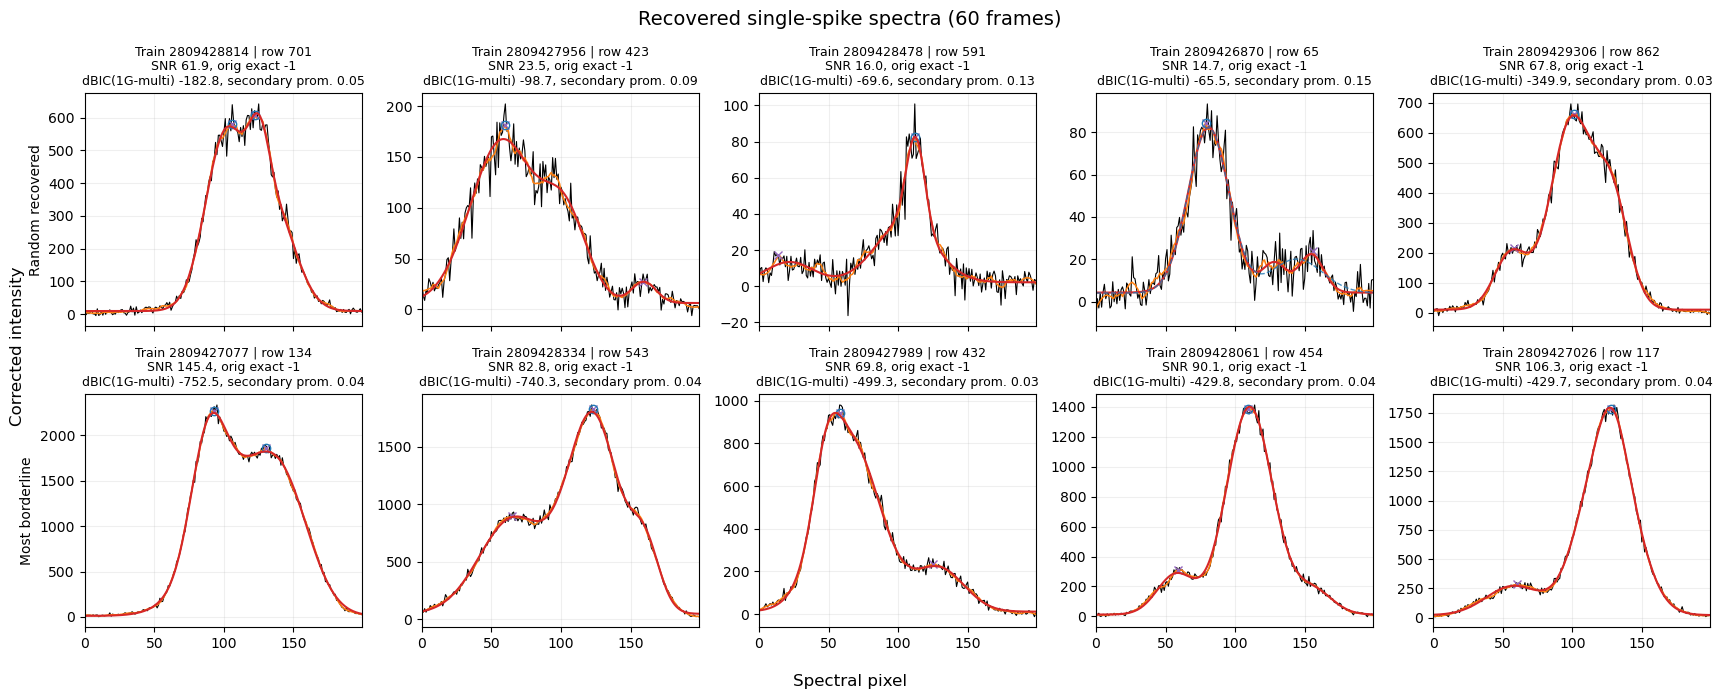

In [87]:
rng = np.random.default_rng(42)
N_PLOT = 5

ids = recovered_single_ids.copy()

if len(ids) == 0:
    print('No recovered single-spike spectra.')
else:

    # borderline = weakest preference for 1 Gaussian over multi-Gaussian
    order = np.lexsort((
        -np.nan_to_num(secondary_ratio[ids], nan=-1),
        np.nan_to_num(single_vs_multi_dbic[ids], nan=np.inf)
    ))

    borderline = ids[order[:N_PLOT]]

    remaining = np.setdiff1d(ids, borderline)

    if len(remaining):
        random_ids = rng.choice(
            remaining,
            size=min(N_PLOT, len(remaining)),
            replace=False
        )
    else:
        random_ids = np.array([], dtype=int)

    fig, axs = plt.subplots(
        2, N_PLOT,
        figsize=(3.5*N_PLOT, 7.0),
        sharex=True,
        squeeze=False
    )

    for ax in axs.flat:
        ax.set_visible(False)

    for row, selected in enumerate([random_ids, borderline]):

        for ax, i in zip(axs[row], selected):

            ax.set_visible(True)

            s = spectra_corr[i]
            y = savgol_filter(s, SG_WINDOW, SG_ORDER)

            # original first-pass info
            _, exact0, p, rp, pairs, m, snr = results[i]

            # Gaussian info
            info = gaussian_results[i]

            ax.plot(pixels, s, color='k', lw=0.8)
            ax.plot(pixels, y, color='C1', lw=1.1)

            # mark original strict / relaxed peaks
            ax.plot(rp, y[rp], 'x', color='C4')
            ax.plot(p, y[p], 'o', mfc='none', color='C0')

            if 'fits' in info:

                fits = info['fits']
                best_bic = min(f['bic'] for f in fits)
                best_fit = min(fits, key=lambda f: f['bic'])

                # best fit
                ax.plot(
                    pixels, best_fit['fit'],
                    color='C3', lw=1.5
                )

                # other competitive fits
                for fit in fits:

                    delta = fit['bic'] - best_bic

                    if delta <= BIC_RANGE and fit is not best_fit:
                        ax.plot(
                            pixels, fit['fit'],
                            '--', lw=1.0, alpha=0.8
                        )

            title = (
                f'Train {frame_index[i]} | row {frame_row[i]}\n'
                f'SNR {snr:.1f}, orig exact {exact0}\n'
                f'dBIC(1G-multi) {single_vs_multi_dbic[i]:.1f}, '
                f'secondary prom. {secondary_ratio[i]:.2f}'
            )

            ax.set_title(title, fontsize=9)
            ax.set_xlim(0, n_spectral - 1)
            ax.grid(alpha=0.2)

    fig.suptitle(
        f'Recovered single-spike spectra ({len(ids)} frames)',
        fontsize=14
    )

    axs[0, 0].set_ylabel('Random recovered')
    axs[1, 0].set_ylabel('Most borderline')

    fig.supxlabel('Spectral pixel')
    fig.supylabel('Corrected intensity')

    fig.tight_layout()
    plt.show()

Showing recovered singles 10 to 19 of 59


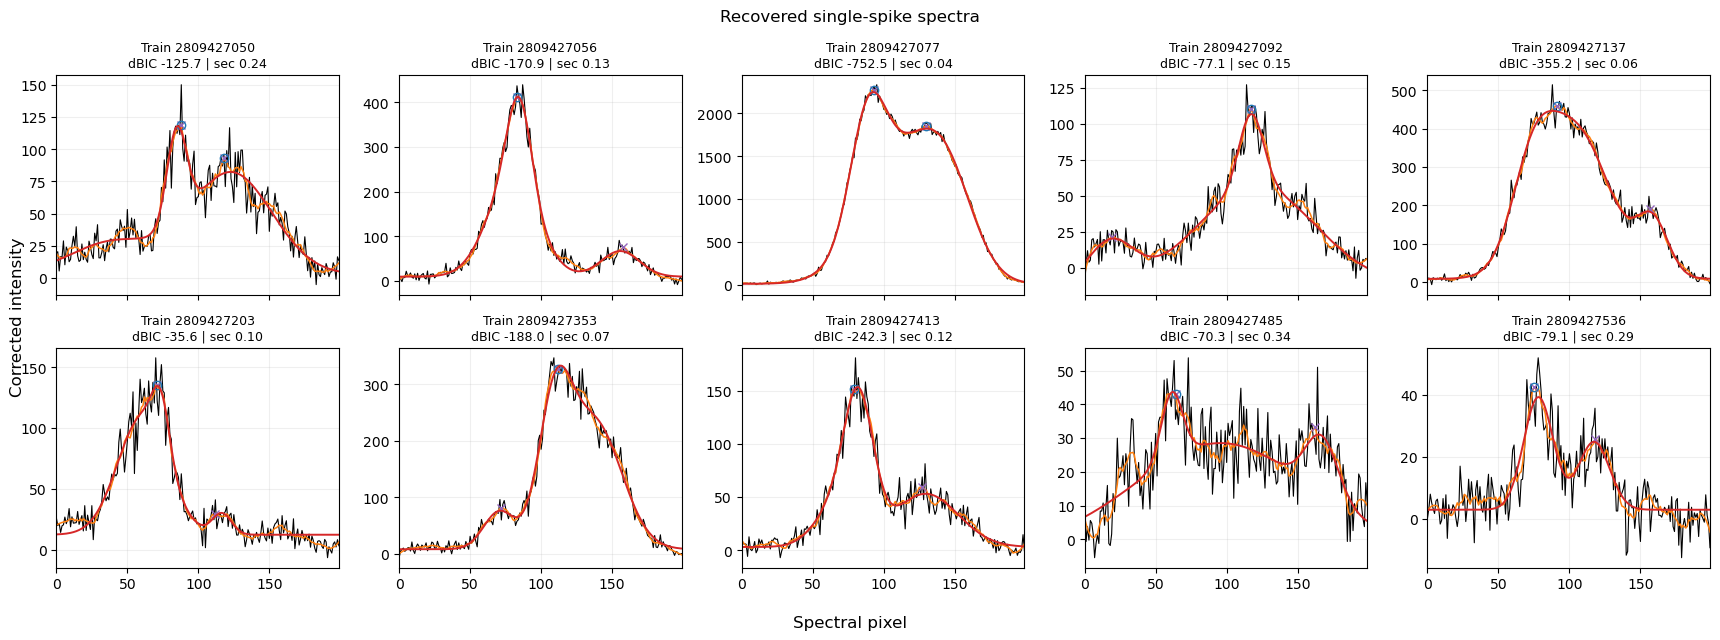

In [100]:
PAGE = 1      # change to 1, 2, 3, ...
PER_PAGE = 10

ids = recovered_single_ids.copy()

start = PAGE * PER_PAGE
stop = min(start + PER_PAGE, len(ids))

selected = ids[start:stop]

print(f'Showing recovered singles {start} to {stop-1} of {len(ids)-1}')

if len(selected) == 0:
    print('Nothing on this page.')
else:

    ncols = 5
    nrows = int(np.ceil(len(selected) / ncols))

    fig, axs = plt.subplots(
        nrows, ncols,
        figsize=(3.5*ncols, 3.2*nrows),
        sharex=True,
        squeeze=False
    )

    for ax in axs.flat:
        ax.set_visible(False)

    for ax, i in zip(axs.flat, selected):

        ax.set_visible(True)

        s = spectra_corr[i]
        y = savgol_filter(s, SG_WINDOW, SG_ORDER)

        _, exact0, p, rp, pairs, m, snr = results[i]

        info = gaussian_results[i]

        ax.plot(pixels, s, color='k', lw=0.8)
        ax.plot(pixels, y, color='C1', lw=1.1)

        ax.plot(rp, y[rp], 'x', color='C4')
        ax.plot(p, y[p], 'o', mfc='none', color='C0')

        if 'fits' in info:
            best_fit = min(info['fits'], key=lambda f: f['bic'])
            ax.plot(pixels, best_fit['fit'], color='C3', lw=1.4)

        ax.set_title(
        
            f'Train {frame_index[i]}\n'
            f'dBIC {single_vs_multi_dbic[i]:.1f} | '
            f'sec {secondary_ratio[i]:.2f}',
            fontsize=9
        )

        ax.set_xlim(0, n_spectral - 1)
        ax.grid(alpha=0.2)

    fig.suptitle('Recovered single-spike spectra')
    fig.supxlabel('Spectral pixel')
    fig.supylabel('Corrected intensity')

    fig.tight_layout()
    plt.show()

### 6.5 Sensitivity to smoothing and valley thresholds
Change one parameter at a time, retaining the same denominator. Use this to assess robustness, not to select the settings that maximise the multiple fraction. Re-run section 6 with alternative spatial ROIs and with background subtraction off as additional checks.

In [80]:
tests = [
    ('Nominal', SG_WINDOW, STRICT),

    # Smoothing
    ('SG 7', 7, STRICT),
    ('SG 9', 9, STRICT),
    ('SG 13', 13, STRICT),
    ('SG 15', 15, STRICT),

    # Relative peak height
    ('Height 15%', SG_WINDOW, dict(STRICT, min_height=0.15)),
    ('Height 20%', SG_WINDOW, dict(STRICT, min_height=0.20)),
    ('Height 30%', SG_WINDOW, dict(STRICT, min_height=0.30)),

    # Combined smoothing and height
    ('SG 15 + H20%', 15, dict(STRICT, min_height=0.20)),
    ('SG 15 + H15%', 15, dict(STRICT, min_height=0.15)),

    # Valley depth
    ('Valley 5%', SG_WINDOW, dict(STRICT, min_drop=0.05)),
    ('Valley 12%', SG_WINDOW, dict(STRICT, min_drop=0.12)),

    # Peak prominence
    ('Prominence 2s', SG_WINDOW, dict(STRICT, min_prom_sigma=2.0)),
    ('Prominence 4s', SG_WINDOW, dict(STRICT, min_prom_sigma=4.0)),
    ('Rel. prom. 2.5%', SG_WINDOW, dict(STRICT, min_prom_rel=0.025)),

    # Peak width
    ('Width 3 px', SG_WINDOW, dict(STRICT, min_width=3)),
    ('Width 7 px', SG_WINDOW, dict(STRICT, min_width=7)),
]

sensitivity = {}

print(f'{"Test":20s} {"Single %":>10s} {"Multiple %":>12s} '
      f'{"Ambig. %":>10s} {"Weak %":>10s}')
print('-' * 68)

for name, window, cuts in tests:

    r = [classify_spectrum(s, strict=cuts,
                           relaxed=RELAXED, window=window)
         for s in spectra_corr]

    b = np.array([v[0] for v in r])
    exact = np.array([v[1] for v in r])

    sensitivity[name] = dict(binary=b, exact=exact)

    f = [100*np.mean(b == k) for k in (1, 2, -1, 0)]

    print(f'{name:20s} {f[0]:10.2f} {f[1]:12.2f} '
          f'{f[2]:10.2f} {f[3]:10.2f}')

Test                   Single %   Multiple %   Ambig. %     Weak %
--------------------------------------------------------------------
Nominal                   56.13        28.36      14.12       1.39
SG 7                      38.66        37.73      22.92       0.69
SG 9                      45.02        33.80      20.14       1.04
SG 13                     54.86        29.75      14.12       1.27
SG 15                     56.13        28.36      14.12       1.39
Height 15%                56.13        30.56      11.92       1.39
Height 20%                56.13        28.36      14.12       1.39
Height 30%                56.13        24.42      18.06       1.39
SG 15 + H20%              56.13        28.36      14.12       1.39
SG 15 + H15%              56.13        30.56      11.92       1.39
Valley 5%                 56.13        28.82      13.66       1.39
Valley 12%                56.13        28.12      14.35       1.39
Prominence 2s             56.13        29.98      12.50     

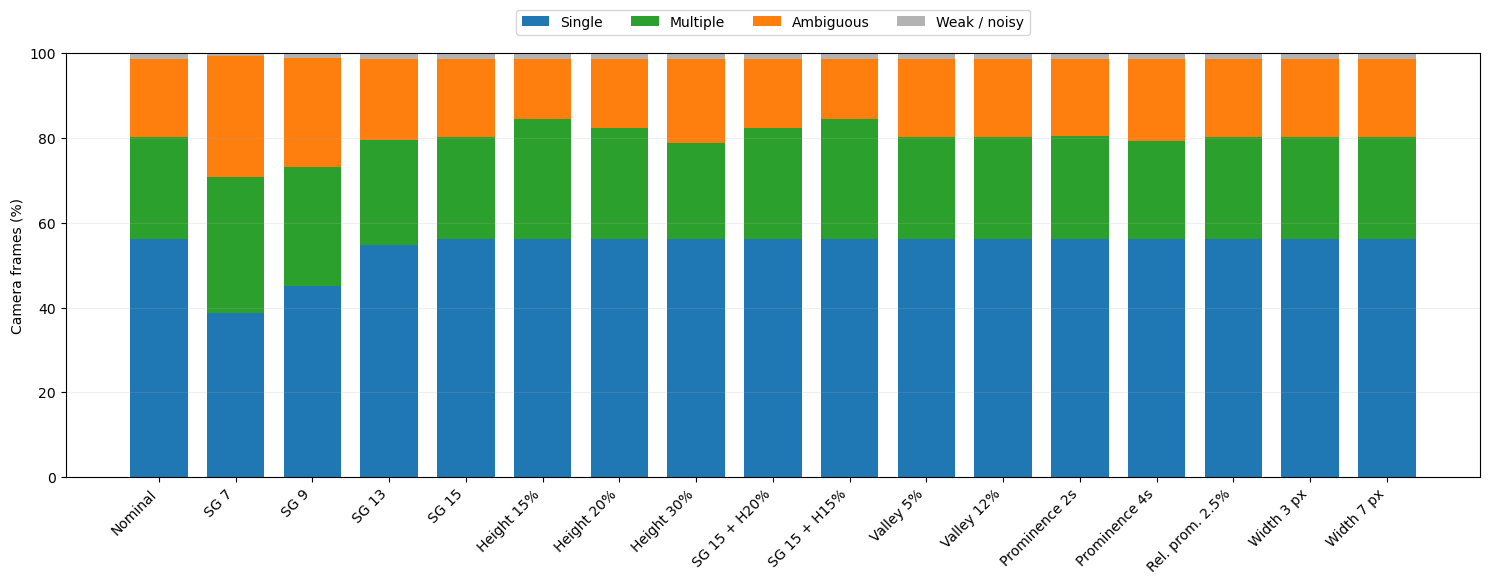

In [43]:
fig, ax = plt.subplots(figsize=(15, 6))

names = list(sensitivity)
x = np.arange(len(names))

bottom = np.zeros(len(names))

for k, label, color in [
    (1, 'Single', 'C0'),
    (2, 'Multiple', 'C2'),
    (-1, 'Ambiguous', 'C1'),
    (0, 'Weak / noisy', '0.7')
]:

    values = np.array([
        100*np.mean(sensitivity[name]['binary'] == k)
        for name in names
    ])

    ax.bar(x, values, bottom=bottom,
           color=color, label=label, width=0.75)

    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha='right')

ax.set_ylabel('Camera frames (%)')
ax.set_ylim(0, 100)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.12),
          ncol=4)

ax.grid(axis='y', alpha=0.2)

fig.tight_layout()
plt.show()

In [44]:
# Investigate only the originally ambiguous spectra

ambiguous_ids = np.flatnonzero(binary == -1)
n_ambiguous = len(ambiguous_ids)

print(f'Ambiguous frames: {n_ambiguous:,} / {len(binary):,}')
print(f'Ambiguous fraction: {100*n_ambiguous/len(binary):.2f}%')

ambiguity_tests = [
    ('Lower peak height', dict(STRICT, min_height=0.15)),
    ('Lower prominence', dict(STRICT,
                              min_prom_sigma=2.0,
                              min_prom_rel=0.025)),
    ('Narrower peaks', dict(STRICT, min_width=3)),
    ('Smaller separation', dict(STRICT, min_distance=5)),
    ('Shallower valley', dict(STRICT, min_drop=0.04)),
    ('Lower valley SNR', dict(STRICT, min_split_sigma=2.0)),
    ('All relaxed cuts', RELAXED.copy()),
]

ambiguity_recovered = {}

print()
print(f'{"Test":22s} {"Single":>8s} {"Multiple":>10s} '
      f'{"Ambiguous":>10s} {"Weak":>8s}')
print('-' * 65)

if n_ambiguous:

    for name, cuts in ambiguity_tests:

        b = np.array([
            classify_spectrum(spectra_corr[i],
                              strict=cuts,
                              relaxed=RELAXED,
                              window=SG_WINDOW)[0]
            for i in ambiguous_ids
        ])

        ambiguity_recovered[name] = ambiguous_ids[b == 2]

        f = [100*np.mean(b == k) for k in (1, 2, -1, 0)]

        print(f'{name:22s} {f[0]:7.1f}% {f[1]:9.1f}% '
              f'{f[2]:9.1f}% {f[3]:7.1f}%')

Ambiguous frames: 158 / 864
Ambiguous fraction: 18.29%

Test                     Single   Multiple  Ambiguous     Weak
-----------------------------------------------------------------
Lower peak height          0.0%      22.8%      77.2%     0.0%
Lower prominence           0.0%       1.3%      98.7%     0.0%
Narrower peaks             0.0%       0.0%     100.0%     0.0%
Smaller separation         0.0%       0.0%     100.0%     0.0%
Shallower valley           0.0%       0.0%     100.0%     0.0%
Lower valley SNR           0.0%      21.5%      78.5%     0.0%
All relaxed cuts           0.0%      67.7%      32.3%     0.0%


Reason                                 Count  % ambiguous
------------------------------------------------------------
Additional relaxed peak                  108       68.35%
Strict peaks, valley failed               45       28.48%
Edge / truncated spectrum                  5        3.16%


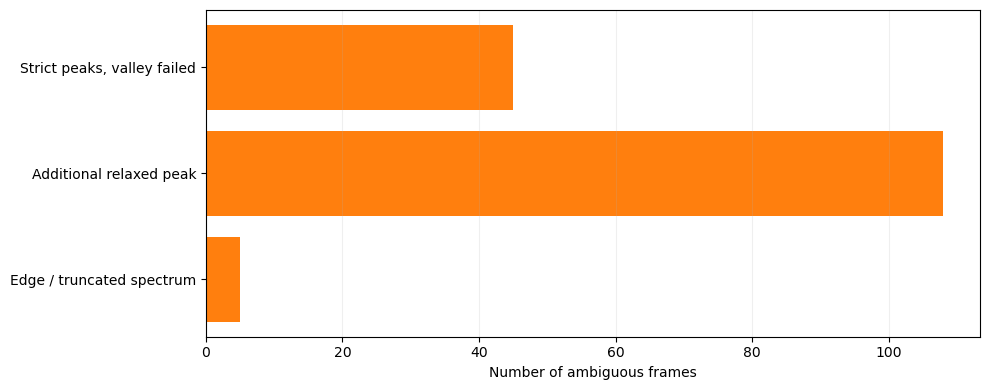

In [45]:
ambiguity_reason = {}

for i in ambiguous_ids:

    s = spectra_corr[i]
    y = savgol_filter(s, SG_WINDOW, SG_ORDER)

    _, exact, p, rp, pairs, m, snr = results[i]

    near_edge = (
        y.argmax() < EDGE_GUARD
        or y.argmax() >= len(y)-EDGE_GUARD
        or np.any(p < EDGE_GUARD)
        or np.any(p >= len(y)-EDGE_GUARD)
        or max(y[:EDGE_GUARD].max(),
               y[-EDGE_GUARD:].max()) >= 0.5*y.max()
    )

    extra = any(
        not np.any(np.abs(p-q) <= STRICT['min_distance']/2)
        for q in rp
    )

    if near_edge:
        reason = 'Edge / truncated spectrum'

    elif len(p) == 0:
        reason = 'No strict peak'

    elif len(p) >= 2 and not pairs:
        reason = 'Strict peaks, valley failed'

    elif extra:
        reason = 'Additional relaxed peak'

    else:
        reason = 'Other'

    ambiguity_reason.setdefault(reason, []).append(i)


print(f'{"Reason":35s} {"Count":>8s} {"% ambiguous":>12s}')
print('-' * 60)

for reason, ids in sorted(ambiguity_reason.items(),
                          key=lambda item: -len(item[1])):

    print(f'{reason:35s} {len(ids):8d} '
          f'{100*len(ids)/n_ambiguous:11.2f}%')


if n_ambiguous:

    fig, ax = plt.subplots(figsize=(10, 4))

    names = list(ambiguity_reason)
    values = [len(ambiguity_reason[name]) for name in names]

    ax.barh(names, values, color='C1')
    ax.set_xlabel('Number of ambiguous frames')
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.2)

    fig.tight_layout()
    plt.show()

Recovered as multiple: 41
Fraction of ambiguous: 25.95%
Fraction of all frames: 4.75%


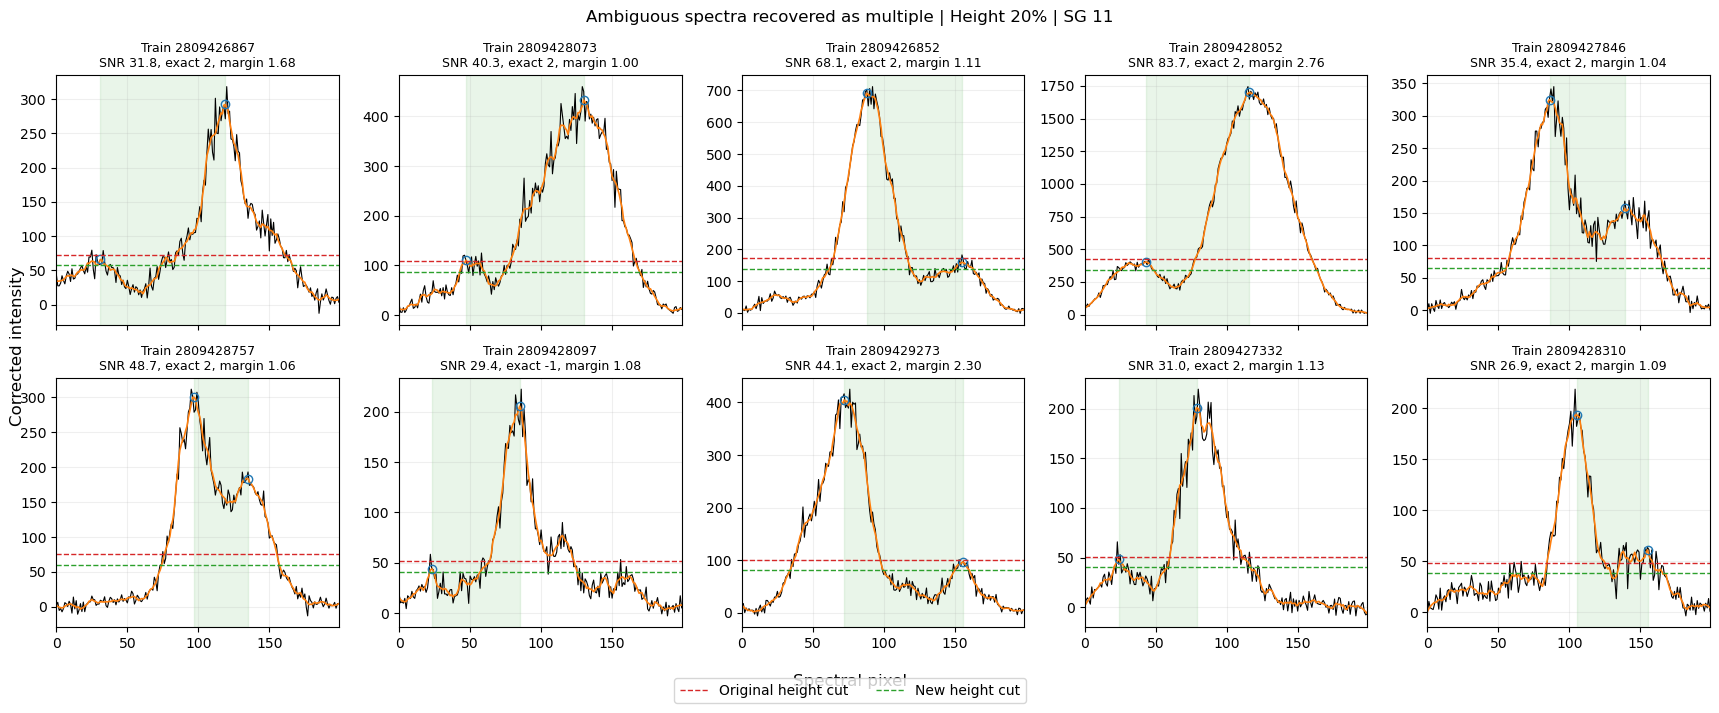

In [48]:
NEW_MIN_HEIGHT = 0.20
NEW_SG_WINDOW = 11

cuts = dict(STRICT, min_height=NEW_MIN_HEIGHT)

recovered = []

for i in ambiguous_ids:

    r = classify_spectrum(
        spectra_corr[i],
        strict=cuts,
        relaxed=RELAXED,
        window=NEW_SG_WINDOW
    )

    if r[0] == 2:
        recovered.append((i, r))


print(f'Recovered as multiple: {len(recovered):,}')

if n_ambiguous:
    print(f'Fraction of ambiguous: '
          f'{100*len(recovered)/n_ambiguous:.2f}%')

print(f'Fraction of all frames: '
      f'{100*len(recovered)/len(binary):.2f}%')


if len(recovered):

    rng = np.random.default_rng(42)

    selected = rng.choice(
        len(recovered),
        size=min(10, len(recovered)),
        replace=False
    )

    fig, axs = plt.subplots(
        2, 5, figsize=(17.5, 7),
        sharex=True, squeeze=False
    )

    for ax in axs.flat:
        ax.set_visible(False)

    for ax, j in zip(axs.flat, selected):

        ax.set_visible(True)

        i, r = recovered[j]

        s = spectra_corr[i]
        y = savgol_filter(s, NEW_SG_WINDOW, SG_ORDER)

        _, exact, p, rp, pairs, m, snr = r

        ax.plot(pixels, s, color='k', lw=0.8)
        ax.plot(pixels, y, color='C1', lw=1.2)

        ax.plot(p, y[p], 'o', mfc='none', color='C0')

        for p1, p2 in pairs:
            ax.axvspan(p1, p2, color='C2', alpha=0.10)

        # Original and new relative height thresholds
        ax.axhline(STRICT['min_height']*y.max(),
                   color='C3', ls='--', lw=1,
                   label='Original height cut')

        ax.axhline(NEW_MIN_HEIGHT*y.max(),
                   color='C2', ls='--', lw=1,
                   label='New height cut')

        ax.set_title(
            f'Train {frame_index[i]}\n'
            f'SNR {snr:.1f}, exact {exact}, margin {m:.2f}',
            fontsize=9
        )

        ax.set_xlim(0, n_spectral-1)
        ax.grid(alpha=0.2)

    handles, labels_plot = axs.flat[0].get_legend_handles_labels()

    fig.legend(handles, labels_plot, loc='lower center',
               ncol=2, bbox_to_anchor=(0.5, -0.02))

    fig.suptitle(
        f'Ambiguous spectra recovered as multiple | '
        f'Height {100*NEW_MIN_HEIGHT:.0f}% | SG {NEW_SG_WINDOW}'
    )

    fig.supxlabel('Spectral pixel')
    fig.supylabel('Corrected intensity')

    fig.tight_layout()
    plt.show()